<a href="https://colab.research.google.com/github/AhtishamAli606/AWS_AIRBNB_SNOWFLAKE_PROJECT/blob/main/Review_Market_GNN_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# 0. SETUP
# ============================================================
!pip install -q yfinance lightgbm

import os, re, gc, time, json, math, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from scipy.stats import rankdata
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, confusion_matrix,
                             classification_report, roc_auc_score)
import networkx as nx
import lightgbm as lgb

import tensorflow as tf
for _gpu in tf.config.list_physical_devices("GPU"):        # let TensorFlow and PyTorch share the GPU
    try:
        tf.config.experimental.set_memory_growth(_gpu, True)
    except Exception:
        pass
import keras
from keras import layers, ops
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="lightgbm")
assert int(keras.__version__.split(".")[0]) >= 3, "Needs Keras 3 (Colab default): !pip install -U keras"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| LightGBM", lgb.__version__,
      "| PyTorch device:", DEVICE)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

TensorFlow 2.21.0 | Keras 3.13.2 | LightGBM 4.6.0 | PyTorch device: cuda
Mounted at /content/drive


In [2]:
# ============================================================
# 1. CONFIGURATION
# ============================================================
REVIEWS_CSV = "/content/drive/MyDrive/Final_Extraction_Reviews.csv"
OUT_DIR     = "/content/drive/MyDrive/review_market_gnn_v2"
FIG_DIR     = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ---- data windows -----------------------------------------------------------------------------
MARKET_START, MARKET_END = "2021-01-01", "2023-12-31"   # stock task (your original window)
BRAND_START = "2018-01-01"                              # brand task can use the longer review history
CLIP_TO_REVIEW_COVERAGE = True
WARMUP_DAYS = 150
USE_PRICE_CACHE = True

DATE_COL, COMPANY_COL, USER_COL = None, None, None      # None = auto-detect
TEXT_COLS = ["title_x", "text"]
INCLUDE_DESCRIPTION = False

# ---- stage 1: transformer -----------------------------------------------------------------------------
TEXT_MODEL = "roberta-base"     # "microsoft/deberta-v3-base" = slightly better, ~2× slower; "distilroberta-base" = fastest
TEXT_MAX_TOKENS = 160
TEXT_EPOCHS = 2
TEXT_LR = 2e-5
TEXT_BATCH = 32
TEXT_TRAIN_CAP = 60_000         # training reviews per cross-fit model
CROSS_FIT_FOLDS = 2
USE_SCORE_CACHE = True          # re-use sentiment scores saved on Drive

# ---- walk-forward evaluation --------------------------------------------------------------------------
WF_FOLDS = 4                    # stock task: 4 test quarters
WF_TEST_DAYS, WF_VAL_DAYS = 63, 63
BRAND_WF_FOLDS = 4              # brand task: 4 test quarters
BRAND_TEST_WEEKS, BRAND_VAL_WEEKS = 13, 13

# ---- stock task ---------------------------------------------------------------------------------------
HORIZON_CANDIDATES = (1, 5, 10, 20)
AUTO_HORIZON = True             # pick the horizon with the best validation IC (LightGBM, fold 1 only)
HORIZON = 5                     # used when AUTO_HORIZON = False
LOOKBACK = 40
ALIGN_TIMEZONES = True
TOP_K_BACKTEST = 4

# ---- brand task ---------------------------------------------------------------------------------------
BRAND_LOOKBACK = 26             # weeks of history per sample
BRAND_HORIZON = 4               # forecast the next 4 weeks
MIN_REVIEWS_FOR_STARS = 8       # need ≥ 8 reviews in both 4-week windows to score a star-rating change

# ---- graph + models -----------------------------------------------------------------------------------
CORR_TOP_K, CORR_MIN = 3, 0.30
COREVIEW_TOP_K, COREVIEW_MIN_USERS = 3, 5
HP = dict(price_units=32, review_units=16, hidden=32, heads=4, gnn_layers=2,
          dropout=0.25, lr=1e-3, weight_decay=1e-4)
GNN_EPOCHS, GNN_BATCH, GNN_PATIENCE = 200, 32, 20
GNN_GRID = [dict(hidden=h, dropout=d) for h in (16, 32, 64) for d in (0.15, 0.35)]
LGB_GRID = [dict(num_leaves=nl, min_child_samples=mc) for nl in (7, 15, 31) for mc in (30, 100)]
N_SEEDS = 2                     # GNN seeds per fold (averaged)
SEED = 42

In [3]:
# ============================================================
# 1b. COMPANIES, BRAND MATCHING, INDUSTRY GROUPS (same as v1)
# ============================================================
TICKERS = {
    "ASUS": "2357.TW", "Acer": "2353.TW", "Nikon": "7731.T", "Casio": "6952.T",
    "Panasonic": "6752.T", "Fujitsu": "6702.T", "LG": "066570.KS", "Samsung": "005930.KS",
    "Xiaomi": "1810.HK", "Universal Electronics": "UEIC", "Sonos": "SONO", "Sony": "6758.T",
    "Nintendo": "7974.T", "Lenovo": "0992.HK", "Logitech": "LOGI", "Koss": "KOSS",
    "Garmin": "GRMN", "GoPro": "GPRO", "HP": "HPQ", "Dell": "DELL",
    "Amazon": "AMZN", "Microsoft": "MSFT", "Google": "GOOGL",
}
BRAND_PATTERNS = {
    "ASUS": r"^asus|^rog\b", "Acer": r"^acer\b", "Nikon": r"^nikon", "Casio": r"^casio|^g-shock",
    "Panasonic": r"^panasonic|^lumix", "Fujitsu": r"^fujitsu|^scansnap", "LG": r"^lg\b",
    "Samsung": r"^samsung", "Xiaomi": r"^xiaomi|^redmi",
    "Universal Electronics": r"^universal electronics|^one for all", "Sonos": r"^sonos",
    "Sony": r"^sony|^playstation", "Nintendo": r"^nintendo", "Lenovo": r"^lenovo|^thinkpad",
    "Logitech": r"^logitech|^logi\b|^ultimate ears|^astro gaming", "Koss": r"^koss",
    "Garmin": r"^garmin", "GoPro": r"^gopro|^go pro", "HP": r"^hp\b|^hewlett|^hyperx|^omen\b",
    "Dell": r"^dell\b|^alienware",
    "Amazon": r"^amazon|^echo\b|^kindle|^fire tv|^ring\b|^eero|^blink\b",
    "Microsoft": r"^microsoft|^xbox|^surface\b", "Google": r"^google|^nest\b|^fitbit|^pixel\b",
}
BRAND_REGEX = {k: re.compile(v) for k, v in BRAND_PATTERNS.items()}
INDUSTRY_GROUPS = {
    "PCs & laptops":        ["ASUS", "Acer", "Lenovo", "HP", "Dell", "Fujitsu", "Microsoft"],
    "Electronics majors":   ["Sony", "Panasonic", "LG", "Samsung", "Xiaomi"],
    "Cameras & imaging":    ["Nikon", "GoPro", "Sony", "Panasonic"],
    "Gaming":               ["Nintendo", "Sony", "Microsoft", "Logitech"],
    "Audio & home AV":      ["Sonos", "Koss", "Sony", "Universal Electronics"],
    "Wearables & watches":  ["Garmin", "Casio", "Google", "Samsung", "Xiaomi"],
    "Platforms & cloud":    ["Amazon", "Microsoft", "Google"],
    "Smart home":           ["Amazon", "Google", "Sonos", "Universal Electronics"],
}

def region_of(ticker):
    for suffix, region in ((".TW", "TW"), (".T", "JP"), (".KS", "KR"), (".HK", "HK")):
        if ticker.endswith(suffix):
            return region
    return "US"

def normalise_brand(x):
    s = str(x).strip().lower()
    s = re.sub(r"^visit the\s+", "", s)
    return re.sub(r"\s+store$", "", s).strip()

def map_brand(raw):
    s = normalise_brand(raw)
    if not s or s in ("nan", "none", "unknown"):
        return None
    for company, rx in BRAND_REGEX.items():
        if rx.search(s):
            return company
    return None

def brand_from_details(d):
    m = re.search(r"""['"](?:Brand|Brand Name|Manufacturer)['"]\s*:\s*['"]([^'"]+)['"]""", str(d))
    return m.group(1) if m else None

In [4]:
# ============================================================
# 1c. PLOT STYLE
# ============================================================
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#e8f1fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_red_blue",   # negative = red, positive = blue
                                        ["#8c1d1d", "#e34948", "#f5b9b8", "#f0efec", "#b7d3f6", "#3987e5", "#104281"])
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "axes.prop_cycle": mpl.cycler(color=SERIES), "figure.dpi": 110, "font.family": "sans-serif",
})

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

def heatmap(ax, M, row_labels, col_labels, cmap, norm=None, vmin=None, vmax=None,
            cbar_label="", xtick_step=1, xrot=90, annotate=None):
    kw = dict(norm=norm) if norm is not None else dict(vmin=vmin, vmax=vmax)
    im = ax.imshow(M, aspect="auto", cmap=cmap, interpolation="nearest", **kw)
    ax.set_yticks(range(len(row_labels)), labels=row_labels)
    xt = list(range(0, len(col_labels), xtick_step))
    ax.set_xticks(xt, labels=[col_labels[i] for i in xt], rotation=xrot)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.015)
    cb.set_label(cbar_label, color=INK2)
    cb.outline.set_visible(False)
    if annotate is not None:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                rgba = im.cmap(im.norm(M[i, j]))
                lum = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
                ax.text(j, i, annotate.format(M[i, j]), ha="center", va="center", fontsize=8,
                        color="white" if lum < 0.5 else INK)
    return im

MONTH_END = "ME" if tuple(int(p) for p in pd.__version__.split(".")[:2]) >= (2, 2) else "M"

Loaded 1,132,008 rows
Columns: ['rating', 'title_x', 'text', 'timestamp', 'title_y', 'average_rating', 'features', 'description', 'company']

Date column: 'timestamp' | company column: 'company' | user column: None
Reviews mapped to a listed company: 1,132,008 / 1,132,008 (100.0%)

Top unmapped brands (extend BRAND_PATTERNS if needed):
Series([], )

Review coverage: 2021-01-01 → 2023-09-13
Stock-task window: 2021-01-01 → 2023-09-13
Brand-task window: 2021-01-01 → 2023-09-13


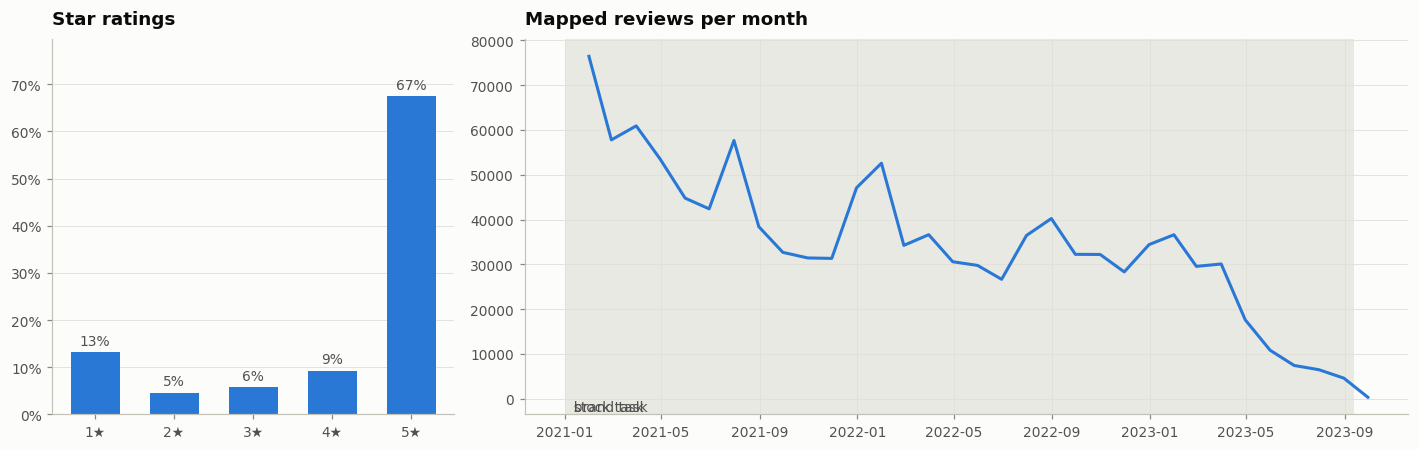

In [5]:
def first_present(columns, candidates):
    lower = {str(c).lower(): c for c in columns}
    for c in candidates:
        if c in columns:
            return c
        if c.lower() in lower:
            return lower[c.lower()]
    return None

def parse_review_dates(s):
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() > 0.9:
        d = pd.to_datetime(num, unit="ms" if num.median() > 1e11 else "s", errors="coerce")
    else:
        try:
            d = pd.to_datetime(s, errors="coerce", utc=True, format="mixed")
        except (TypeError, ValueError):
            d = pd.to_datetime(s, errors="coerce", utc=True)
        d = d.dt.tz_convert(None)
    return d.dt.normalize().astype("datetime64[ns]")

reviews = pd.read_csv(REVIEWS_CSV, low_memory=False)
print(f"Loaded {len(reviews):,} rows\nColumns: {list(reviews.columns)}")
reviews["rating"] = pd.to_numeric(reviews["rating"], errors="coerce")
reviews = reviews.dropna(subset=["rating"]).reset_index(drop=True)
reviews["rating"] = reviews["rating"].round().clip(1, 5).astype(int)

DATE_COL    = DATE_COL    or first_present(reviews.columns, ["timestamp", "date", "review_date", "unixReviewTime",
                                                             "reviewTime", "sort_timestamp", "time"])
COMPANY_COL = COMPANY_COL or first_present(reviews.columns, ["store", "brand", "company", "manufacturer"])
USER_COL    = USER_COL    or first_present(reviews.columns, ["user_id", "reviewerID", "reviewer_id"])
if DATE_COL is None:
    raise ValueError("No review-date column found; set DATE_COL in section 1.")
print(f"\nDate column: {DATE_COL!r} | company column: {COMPANY_COL!r} | user column: {USER_COL!r}")
reviews["date"] = parse_review_dates(reviews[DATE_COL])
reviews = reviews.dropna(subset=["date"]).reset_index(drop=True)

text_cols = [c for c in TEXT_COLS if c in reviews.columns]
if INCLUDE_DESCRIPTION and "description" in reviews.columns:
    text_cols.append("description")
if not text_cols:
    raise ValueError(f"None of TEXT_COLS={TEXT_COLS} exist in the CSV.")
HTML_RE, URL_RE = re.compile(r"<[^>]+>"), re.compile(r"http\S+|www\.\S+")
txt = reviews[text_cols[0]].fillna("").astype(str)
for c in text_cols[1:]:
    txt = txt + ". " + reviews[c].fillna("").astype(str)
reviews["raw_text"] = (txt.str.replace(HTML_RE, " ", regex=True).str.replace(URL_RE, " ", regex=True)
                          .str.replace(r"\s+", " ", regex=True).str.strip(" ."))

if COMPANY_COL is not None:
    raw_brand = reviews[COMPANY_COL]
elif "details" in reviews.columns:
    raw_brand = reviews["details"].map(brand_from_details)
    COMPANY_COL = "details → Brand"
else:
    raise ValueError("No brand/store column found; set COMPANY_COL in section 1.")
brand_map = {b: map_brand(b) for b in pd.Series(raw_brand.dropna().unique())}
reviews["company"] = raw_brand.map(brand_map)
mapped = reviews["company"].notna()
print(f"Reviews mapped to a listed company: {mapped.sum():,} / {len(reviews):,} ({mapped.mean():.1%})")
print("\nTop unmapped brands (extend BRAND_PATTERNS if needed):")
print(raw_brand[~mapped].value_counts().head(12).to_string())

rev_m = reviews[mapped]
cov_start, cov_end = rev_m["date"].min(), rev_m["date"].max()
STOCK_WIN = [pd.Timestamp(MARKET_START), pd.Timestamp(MARKET_END)]
BRAND_WIN = [pd.Timestamp(BRAND_START), cov_end]
if CLIP_TO_REVIEW_COVERAGE:
    STOCK_WIN = [max(STOCK_WIN[0], cov_start), min(STOCK_WIN[1], cov_end)]
BRAND_WIN[0] = max(BRAND_WIN[0], cov_start)
print(f"\nReview coverage: {cov_start.date()} → {cov_end.date()}")
print(f"Stock-task window: {STOCK_WIN[0].date()} → {STOCK_WIN[1].date()}")
print(f"Brand-task window: {BRAND_WIN[0].date()} → {BRAND_WIN[1].date()}")

# Figure 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1, 2.2]))
share = reviews["rating"].value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
ax = axes[0]
ax.bar([f"{s}★" for s in share.index], share.values, color=SERIES[0], width=0.62)
for i, v in enumerate(share.values):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_ylim(0, share.max() * 1.18)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("Star ratings")
ax.grid(axis="x", visible=False)
ax = axes[1]
monthly = rev_m.set_index("date").resample(MONTH_END).size()
ax.plot(monthly.index, monthly.values, color=SERIES[0])
ax.axvspan(BRAND_WIN[0], BRAND_WIN[1], color=GRID, alpha=0.3, lw=0)
ax.axvspan(STOCK_WIN[0], STOCK_WIN[1], color=GRID, alpha=0.5, lw=0)
ax.text(BRAND_WIN[0], ax.get_ylim()[0], "  brand task", color=INK2, fontsize=9, va="bottom")
ax.text(STOCK_WIN[0], ax.get_ylim()[0], "  stock task", color=INK2, fontsize=9, va="bottom")
ax.set_title("Mapped reviews per month")
fig.tight_layout()
savefig(fig, "01_review_data")

Using cached prices: /content/drive/MyDrive/review_market_gnn_v2/close_2020-08-04_2023-10-28.csv

Panel: 843 trading days × 23 companies | 2020-08-04 → 2023-10-27


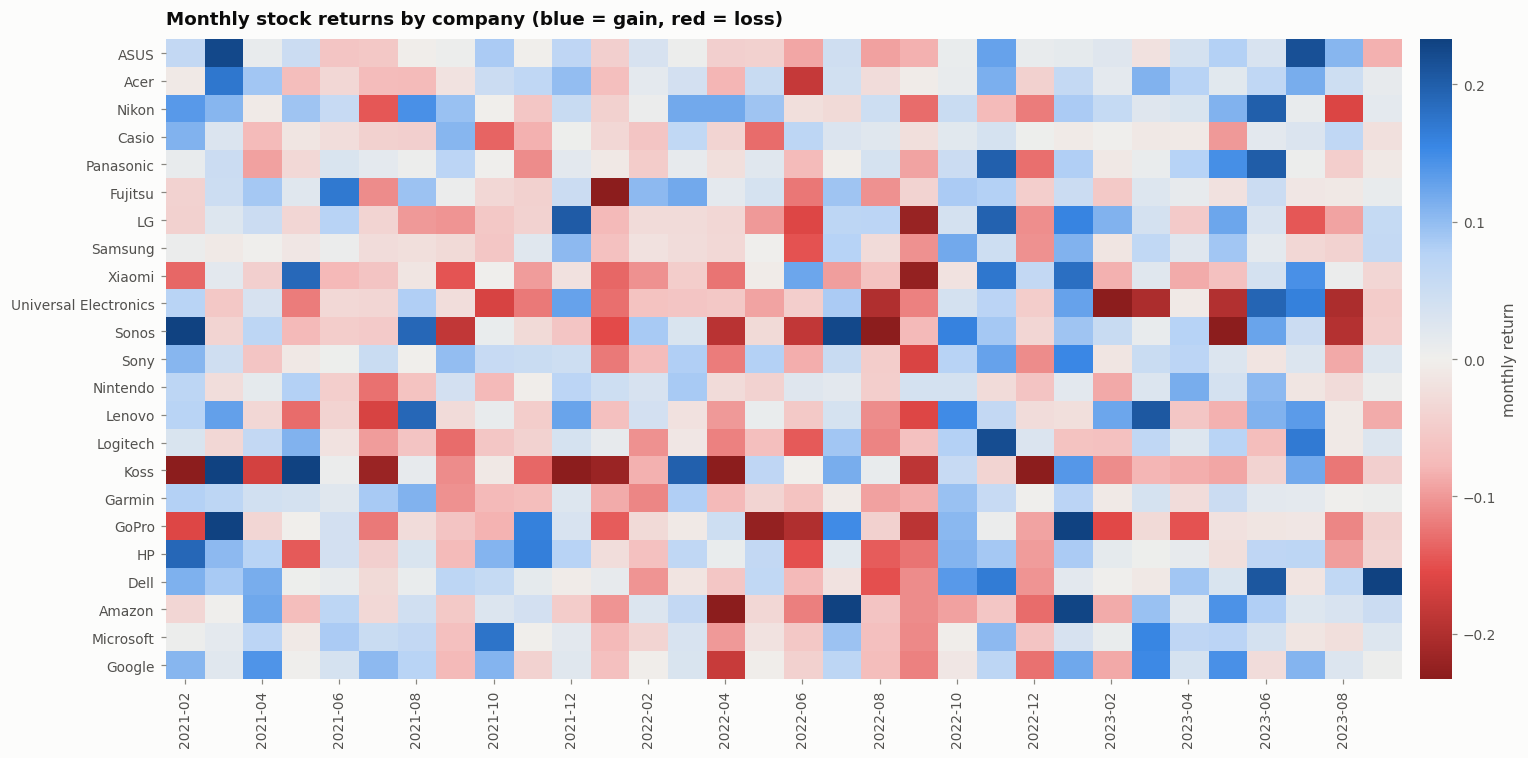

In [6]:
def _extract(raw, ticker, field):
    if raw is None or len(raw) == 0:
        return None
    cols = raw.columns
    if isinstance(cols, pd.MultiIndex):
        for key in ((ticker, field), (field, ticker)):
            if key in cols:
                s = raw[key]
                return s if s.notna().any() else None
        return None
    return raw[field] if field in cols and raw[field].notna().any() else None

def _clean_index(s):
    idx = pd.to_datetime(s.index)
    if getattr(idx, "tz", None) is not None:
        idx = idx.tz_localize(None)
    s = s.copy()
    s.index = idx.normalize()
    return s[~s.index.duplicated(keep="last")].astype(float)

def download_market(tickers, start, end, cache_dir):
    cpath = os.path.join(cache_dir, f"close_{start}_{end}.csv")
    vpath = os.path.join(cache_dir, f"volume_{start}_{end}.csv")
    if USE_PRICE_CACHE and os.path.exists(cpath) and os.path.exists(vpath):
        print("Using cached prices:", cpath)
        return (pd.read_csv(cpath, index_col=0, parse_dates=True), pd.read_csv(vpath, index_col=0, parse_dates=True))
    import yfinance as yf
    try:
        raw = yf.download(list(tickers.values()), start=start, end=end, auto_adjust=True,
                          group_by="ticker", progress=False, threads=True)
    except Exception as e:
        print("Batch download failed:", e)
        raw = None
    close, volume = {}, {}
    for name, tk in tickers.items():
        c, v = _extract(raw, tk, "Close"), _extract(raw, tk, "Volume")
        attempt = 0
        while c is None and attempt < 3:
            attempt += 1
            try:
                h = yf.Ticker(tk).history(start=start, end=end, auto_adjust=True)
                if len(h) and h["Close"].notna().any():
                    c, v = h["Close"], h["Volume"] if "Volume" in h else None
            except Exception as e:
                print(f"  {tk}: attempt {attempt} failed ({e})")
            if c is None:
                time.sleep(2 * attempt)
        if c is None:
            print(f"  ✗ {name} ({tk}): no data, dropped")
            continue
        close[name] = _clean_index(c)
        if v is not None:
            volume[name] = _clean_index(v)
    close = pd.DataFrame(close).sort_index()
    volume = pd.DataFrame(volume).reindex(index=close.index, columns=close.columns)
    close.to_csv(cpath)
    volume.to_csv(vpath)
    return close, volume

DL_START = (min(STOCK_WIN[0], BRAND_WIN[0]) - pd.Timedelta(days=WARMUP_DAYS)).strftime("%Y-%m-%d")
DL_END = min(max(STOCK_WIN[1], BRAND_WIN[1]) + pd.Timedelta(days=45), pd.Timestamp.today().normalize()).strftime("%Y-%m-%d")
close_raw, volume_raw = download_market(TICKERS, DL_START, DL_END, OUT_DIR)
close_raw = close_raw.loc[close_raw.notna().any(axis=1)]
in_win = (close_raw.index >= STOCK_WIN[0]) & (close_raw.index <= STOCK_WIN[1])
coverage = close_raw.loc[in_win].notna().mean()
NODES = [n for n in TICKERS if n in coverage.index and coverage[n] >= 0.6]
for n in TICKERS:
    if n not in NODES:
        print(f"  ✗ {n}: too few quotes, dropped")
close_raw = close_raw[NODES]
close_raw = close_raw.loc[close_raw.notna().any(axis=1)]
volume_raw = volume_raw.reindex(index=close_raw.index, columns=NODES)

CAL = pd.DatetimeIndex(close_raw.index)
T, N = len(CAL), len(NODES)
NODE_ID = {n: i for i, n in enumerate(NODES)}
REGION = np.array([region_of(TICKERS[n]) for n in NODES])
TRADED = close_raw.notna().to_numpy()
CLOSE = close_raw.ffill().to_numpy()
VOLUME = volume_raw.to_numpy(dtype=float)
logp = np.log(CLOSE)
print(f"\nPanel: {T} trading days × {N} companies | {CAL[0].date()} → {CAL[-1].date()}")

# Figure 2
px = pd.DataFrame(CLOSE, index=CAL, columns=NODES).loc[STOCK_WIN[0]:STOCK_WIN[1]]
mret = px.resample(MONTH_END).last().pct_change().iloc[1:]
lim = float(np.nanpercentile(np.abs(mret.to_numpy()), 98))
fig, ax = plt.subplots(figsize=(14, 7))
heatmap(ax, mret.T.to_numpy(), NODES, [d.strftime("%Y-%m") for d in mret.index], DIV,
        norm=TwoSlopeNorm(0, -lim, lim), cbar_label="monthly return", xtick_step=2)
ax.set_title("Monthly stock returns by company (blue = gain, red = loss)")
fig.tight_layout()
savefig(fig, "02_monthly_returns")

⚠ Brand task: using 4 folds × 12-week test blocks (asked for 4 × 13; history is short).

Stock task folds
  fold 1: train 2021-01-04→2022-05-02 (346) | val 2022-06-01→2022-08-26 | test 2022-09-27→2022-12-22 (63)
  fold 2: train 2021-01-04→2022-07-28 (409) | val 2022-08-29→2022-11-23 | test 2022-12-23→2023-03-21 (63)
  fold 3: train 2021-01-04→2022-10-25 (472) | val 2022-11-24→2023-02-20 | test 2023-03-22→2023-06-16 (63)
  fold 4: train 2021-01-04→2023-01-20 (535) | val 2023-02-21→2023-05-18 | test 2023-06-19→2023-09-13 (63)

Brand task folds
  fold 1: train 2021-07-04→2022-04-24 (43) | val 2022-05-29→2022-08-14 | test 2022-09-18→2022-12-04 (12)
  fold 2: train 2021-07-04→2022-07-17 (55) | val 2022-08-21→2022-11-06 | test 2022-12-11→2023-02-26 (12)
  fold 3: train 2021-07-04→2022-10-09 (67) | val 2022-11-13→2023-01-29 | test 2023-03-05→2023-05-21 (12)
  fold 4: train 2021-07-04→2023-01-01 (79) | val 2023-02-05→2023-04-23 | test 2023-05-28→2023-08-13 (12)

Transformer trains on reviews b

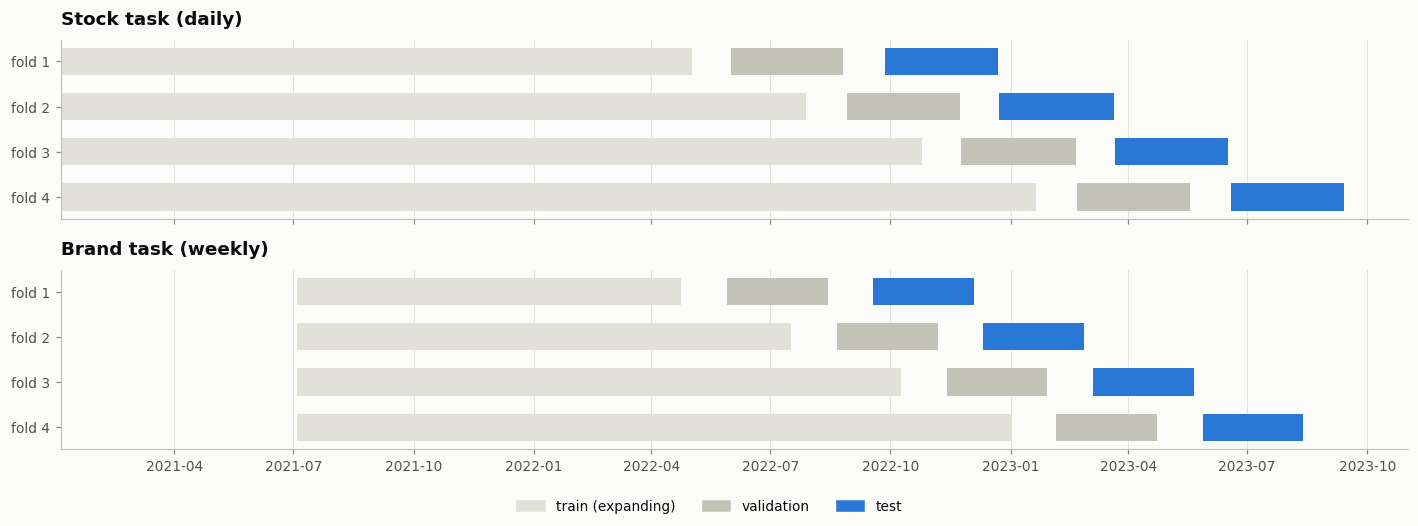

In [7]:
def walk_forward(sample_t, n_folds, test_len, val_len, gap):
    n = len(sample_t)
    first_test = n - n_folds * test_len
    folds = []
    for k in range(n_folds):
        te0 = first_test + k * test_len
        te1 = te0 + test_len if k < n_folds - 1 else n
        va1 = te0 - gap
        va0 = va1 - val_len
        tr1 = va0 - gap
        if va0 < 0 or tr1 < 3 * val_len:
            raise ValueError("Not enough history for this many folds; lower the fold count or block lengths.")
        folds.append(dict(train=sample_t[:tr1], val=sample_t[va0:va1], test=sample_t[te0:te1]))
    return folds

def fit_folds(sample_t, n_folds, test_len, val_len, gap, min_len=6):
    """Shorten the test/val blocks first, then use fewer folds, until the walk-forward fits the data."""
    for k in range(n_folds, 0, -1):
        for tl in range(test_len, min_len - 1, -1):
            try:
                folds = walk_forward(sample_t, k, tl, min(val_len, tl), gap)
            except ValueError:
                continue
            if (k, tl) != (n_folds, test_len):
                print(f"⚠ Brand task: using {k} folds × {tl}-week test blocks "
                      f"(asked for {n_folds} × {test_len}; history is short).")
            return folds
    raise ValueError("Brand history is too short for walk-forward evaluation.")

# ---- stock task (daily) ----
OFFSET = np.where((REGION != "US") & ALIGN_TIMEZONES, 1, 0)       # Asian targets start at the next close
MAX_OFF = int(OFFSET.max())
MAX_H = max(HORIZON_CANDIDATES) if AUTO_HORIZON else HORIZON
s0 = max(LOOKBACK - 1 + 60, int(CAL.searchsorted(STOCK_WIN[0])))
s1 = min(int(CAL.searchsorted(STOCK_WIN[1], side="right")) - 1, T - 1 - MAX_H - MAX_OFF)
STOCK_T = np.arange(s0, s1 + 1)
STOCK_FOLDS = walk_forward(STOCK_T, WF_FOLDS, WF_TEST_DAYS, WF_VAL_DAYS, gap=MAX_H + MAX_OFF)

# ---- brand task (weekly, weeks end on Sunday) ----   ← CHANGED
BRAND_WARMUP_WEEKS = 26                                 # was a fixed 52; your reviews start ~2021, so 52 wastes a year
WEEKS = pd.date_range(BRAND_WIN[0], BRAND_WIN[1], freq="W-SUN")
W = len(WEEKS)
b0 = max(BRAND_LOOKBACK - 1, BRAND_WARMUP_WEEKS)
b1 = W - 1 - BRAND_HORIZON
BRAND_T = np.arange(b0, b1 + 1)
BRAND_FOLDS = fit_folds(BRAND_T, BRAND_WF_FOLDS, BRAND_TEST_WEEKS, BRAND_VAL_WEEKS, gap=BRAND_HORIZON)

for name, folds, cal in (("Stock", STOCK_FOLDS, CAL), ("Brand", BRAND_FOLDS, WEEKS)):
    print(f"\n{name} task folds")
    for k, f in enumerate(folds):
        print(f"  fold {k + 1}: train {cal[f['train'][0]].date()}→{cal[f['train'][-1]].date()} ({len(f['train'])})"
              f" | val {cal[f['val'][0]].date()}→{cal[f['val'][-1]].date()}"
              f" | test {cal[f['test'][0]].date()}→{cal[f['test'][-1]].date()} ({len(f['test'])})")

# The text model may only learn from reviews written before the earliest validation block of either task
TEXT_CUTOFF = min(CAL[STOCK_FOLDS[0]["val"][0]], WEEKS[BRAND_FOLDS[0]["val"][0]] - pd.Timedelta(days=6))
FIRST_TEST = min(CAL[STOCK_FOLDS[0]["test"][0]], WEEKS[BRAND_FOLDS[0]["test"][0]] - pd.Timedelta(days=6))
print(f"\nTransformer trains on reviews before {TEXT_CUTOFF.date()}; it is evaluated on reviews from {FIRST_TEST.date()}")

# Figure 3: fold timeline
fig, axes = plt.subplots(2, 1, figsize=(13, 4.8), sharex=True)
for ax, (name, folds, cal) in zip(axes, (("Stock task (daily)", STOCK_FOLDS, CAL), ("Brand task (weekly)", BRAND_FOLDS, WEEKS))):
    for k, f in enumerate(folds):
        y = len(folds) - k
        for part, color, alpha in (("train", GRID, 1.0), ("val", AXIS, 1.0), ("test", SERIES[0], 1.0)):
            ax.barh(y, (cal[f[part][-1]] - cal[f[part][0]]).days, left=cal[f[part][0]], height=0.6,
                    color=color, alpha=alpha)
    ax.set_yticks(range(1, len(folds) + 1), labels=[f"fold {len(folds) - i}" for i in range(len(folds))])
    ax.set_title(name)
    ax.grid(axis="y", visible=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.legend(handles=[mpl.patches.Patch(color=GRID, label="train (expanding)"),
                    mpl.patches.Patch(color=AXIS, label="validation"),
                    mpl.patches.Patch(color=SERIES[0], label="test")], loc="lower center", ncol=3)
savefig(fig, "03_walk_forward_folds")

In [8]:
def finetune_text_fold(tr_texts, tr_y, va_texts, va_y, class_weight, seed=SEED):
    tok = AutoTokenizer.from_pretrained(TEXT_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(TEXT_MODEL, num_labels=5).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=TEXT_LR, weight_decay=0.01)
    n_steps = TEXT_EPOCHS * math.ceil(len(tr_texts) / TEXT_BATCH)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * n_steps), n_steps)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(class_weight, dtype=torch.float32, device=DEVICE),
                                        label_smoothing=0.05)
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    hist = dict(step=[], train_loss=[], epoch_step=[], val_loss=[], val_acc=[])
    step, running = 0, []
    for epoch in range(TEXT_EPOCHS):
        model.train()
        order = rng.permutation(len(tr_texts))
        t0 = time.time()
        for i in range(0, len(order), TEXT_BATCH):
            j = order[i:i + TEXT_BATCH]
            enc = tok([tr_texts[k] for k in j], truncation=True, max_length=TEXT_MAX_TOKENS,
                      padding=True, return_tensors="pt").to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = model(**enc).logits
            loss = loss_fn(logits.float(), torch.as_tensor(tr_y[j], device=DEVICE))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            running.append(loss.item())
            step += 1
            if step % 100 == 0:
                hist["step"].append(step)
                hist["train_loss"].append(float(np.mean(running[-100:])))
            if step % 500 == 0:
                print(f"    step {step}/{n_steps}  loss {np.mean(running[-500:]):.4f}  ({time.time() - t0:.0f}s)")
        p = predict_text_proba((tok, model), va_texts)
        hist["epoch_step"].append(step)
        hist["val_loss"].append(float(-np.mean(np.log(p[np.arange(len(va_y)), va_y] + 1e-9))))
        hist["val_acc"].append(float(np.mean(p.argmax(1) == va_y)))
        print(f"  epoch {epoch + 1}: val loss {hist['val_loss'][-1]:.4f} | val accuracy {hist['val_acc'][-1]:.3f}")
    return (tok, model), hist

@torch.no_grad()
def predict_text_proba(tm, texts, batch_size=256):
    tok, model = tm
    model.eval()
    use_amp = DEVICE.type == "cuda"
    order = np.argsort([len(t) for t in texts])               # similar lengths per batch → less padding
    out = np.zeros((len(texts), 5), dtype=np.float32)
    for i in range(0, len(order), batch_size):
        j = order[i:i + batch_size]
        enc = tok([texts[k] for k in j], truncation=True, max_length=TEXT_MAX_TOKENS,
                  padding=True, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits = model(**enc).logits
        out[j] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    return out

def free_gpu(*objs):
    for o in objs:
        del o
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [9]:
# ---- 5b. Train (or load cached) sentiment scores --------------------------------------------------------------
rng = np.random.default_rng(SEED)
score_mask = (reviews["company"].isin(NODES)
              & (reviews["date"] >= min(CAL[0], WEEKS[0] - pd.Timedelta(days=6)) - pd.Timedelta(days=3)))
score_idx = reviews.index[score_mask].to_numpy()
safe_name = re.sub(r"[^A-Za-z0-9]+", "-", TEXT_MODEL)
SCORE_PATH = os.path.join(OUT_DIR, f"review_scores_{safe_name}_{TEXT_CUTOFF.date()}_{len(reviews)}.csv.gz")
TEXT_HISTORIES = []

cached = None
if USE_SCORE_CACHE and os.path.exists(SCORE_PATH):
    cached = pd.read_csv(SCORE_PATH, index_col=0)
    ok = cached.index.isin(reviews.index).all() and set(score_idx) <= set(cached.index) and \
        (reviews.loc[cached.index, "rating"].to_numpy() == cached["rating"].to_numpy()).all()
    if ok:
        print("Loaded cached sentiment scores:", SCORE_PATH)
        TEXT_HISTORIES = json.load(open(SCORE_PATH + ".history.json")) if os.path.exists(SCORE_PATH + ".history.json") else []
    else:
        print("Cache does not match the current data; retraining.")
        cached = None

if cached is None:
    K = max(1, CROSS_FIT_FOLDS)
    pre = reviews.index[reviews["date"] < TEXT_CUTOFF].to_numpy()
    fold_of = pd.Series(rng.integers(0, K, len(reviews)), index=reviews.index)     # post-cutoff rows: random model
    texts_all = reviews["raw_text"].to_numpy()
    y_all = reviews["rating"].to_numpy() - 1
    P = np.zeros((len(score_idx), 5), dtype=np.float32)
    for k in range(K):
        pool = pre[fold_of.loc[pre].to_numpy() != k] if K > 1 else pre
        pool = rng.permutation(pool)[: TEXT_TRAIN_CAP + max(2000, TEXT_TRAIN_CAP // 20)]
        n_va = min(max(500, len(pool) // 20), 5000)
        va_rows, tr_rows = pool[:n_va], pool[n_va:]
        counts = np.bincount(y_all[tr_rows], minlength=5)
        cw = np.sqrt(len(tr_rows) / (5 * np.maximum(counts, 1)))
        print(f"\n── transformer {k + 1}/{K}: {len(tr_rows):,} train / {len(va_rows):,} val reviews · {TEXT_MODEL}")
        tm, hist = finetune_text_fold(texts_all[tr_rows], y_all[tr_rows], texts_all[va_rows], y_all[va_rows],
                                      cw.tolist(), seed=SEED + k)
        TEXT_HISTORIES.append(hist)
        rows = score_idx[fold_of.loc[score_idx].to_numpy() == k] if K > 1 else score_idx
        t0 = time.time()
        P[np.isin(score_idx, rows)] = predict_text_proba(tm, texts_all[rows])
        print(f"  scored {len(rows):,} reviews in {time.time() - t0:.0f}s")
        free_gpu(tm)
    cached = pd.DataFrame(P, index=score_idx, columns=[f"p{s}" for s in range(1, 6)])
    cached["rating"] = reviews.loc[score_idx, "rating"].to_numpy()
    cached.to_csv(SCORE_PATH, compression="gzip")
    json.dump(TEXT_HISTORIES, open(SCORE_PATH + ".history.json", "w"))
    print("Saved sentiment scores →", SCORE_PATH)

PROBS = cached.loc[score_idx, [f"p{s}" for s in range(1, 6)]].to_numpy()
review_scores = pd.DataFrame(index=score_idx)
review_scores["exp_rating"] = PROBS @ np.arange(1, 6)
review_scores["sentiment"] = (review_scores["exp_rating"] - 3.0) / 2.0
review_scores["neg_share"] = PROBS[:, 0] + PROBS[:, 1]


── transformer 1/2: 59,850 train / 3,150 val reviews · roberta-base


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (4 outputs left out)

    step 500/3742  loss 1.2114  (123s)
    step 1000/3742  loss 1.0587  (247s)
    step 1500/3742  loss 1.0373  (370s)
  epoch 1: val loss 0.5713 | val accuracy 0.817
    step 2000/3742  loss 1.0135  (33s)
    step 2500/3742  loss 0.9629  (158s)
    step 3000/3742  loss 0.9655  (283s)
    step 3500/3742  loss 0.9492  (406s)
  epoch 2: val loss 0.5614 | val accuracy 0.818
  scored 566,003 reviews in 591s

── transformer 2/2: 59,850 train / 3,150 val reviews · roberta-base


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    step 500/3742  loss 1.2099  (124s)
    step 1000/3742  loss 1.0633  (247s)
    step 1500/3742  loss 1.0375  (371s)
  epoch 1: val loss 0.6540 | val accuracy 0.782
    step 2000/3742  loss 1.0071  (33s)
    step 2500/3742  loss 0.9643  (158s)
    step 3000/3742  loss 0.9646  (283s)
    step 3500/3742  loss 0.9544  (406s)
  epoch 2: val loss 0.5954 | val accuracy 0.799
  scored 566,005 reviews in 595s
Saved sentiment scores → /content/drive/MyDrive/review_market_gnn_v2/review_scores_roberta-base_2022-05-23_1132008.csv.gz


Transformer on 258,518 test-period reviews (never seen in training):
  accuracy_5class      0.7941
  majority_baseline    0.6393
  macro_f1_5class      0.5602
  qwk                  0.9064
  mae_expected_stars   0.4869
  accuracy_3class      0.9105
  macro_f1_3class      0.7406
              precision    recall  f1-score   support

          1★       0.76      0.83      0.79     41189
          2★       0.33      0.29      0.31     13234
          3★       0.39      0.39      0.39     15505
          4★       0.40      0.37      0.38     23330
          5★       0.93      0.92      0.93    165260

    accuracy                           0.79    258518
   macro avg       0.56      0.56      0.56    258518
weighted avg       0.79      0.79      0.79    258518



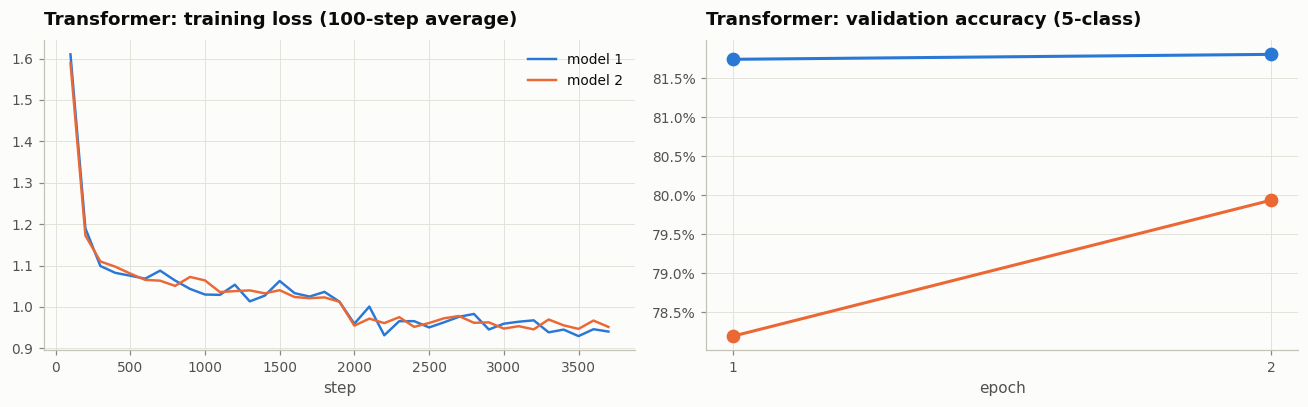

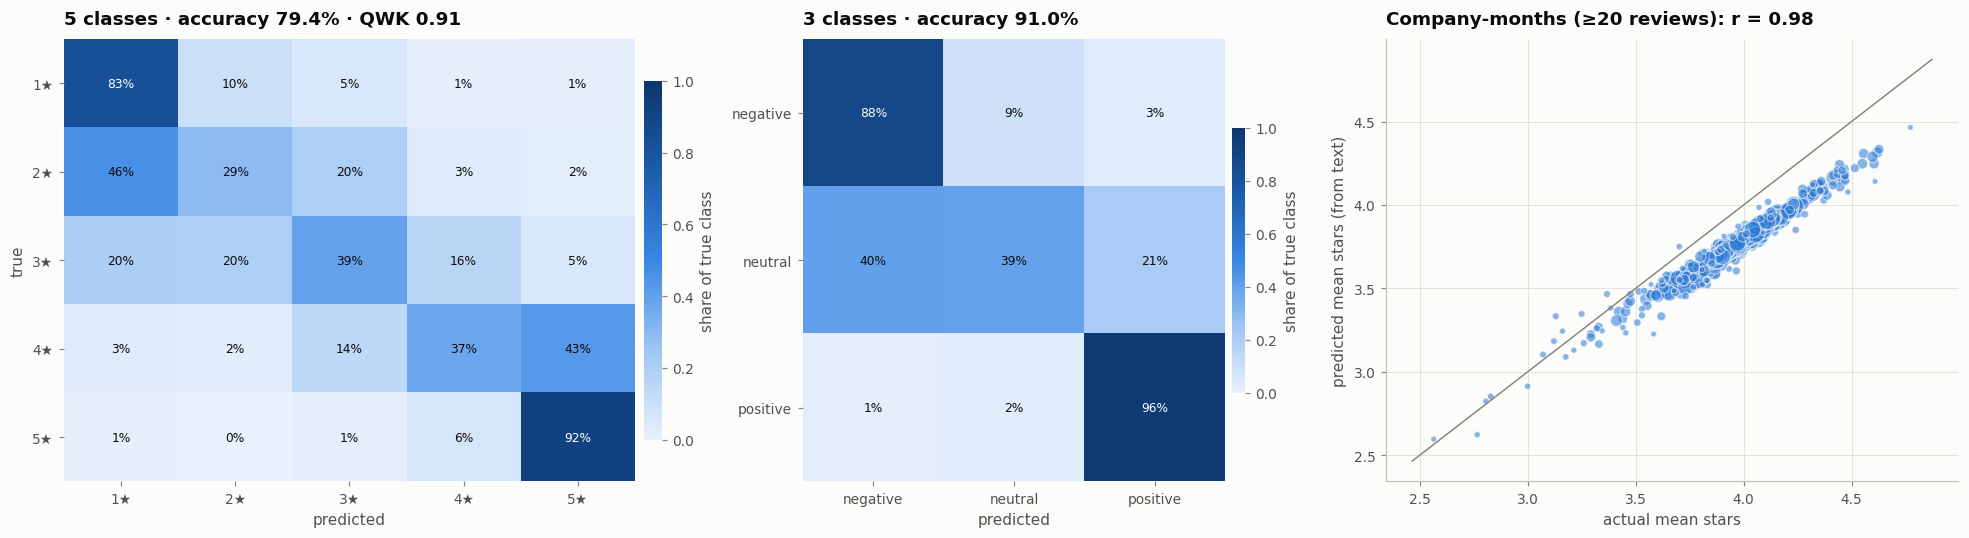

In [10]:
# ---- 5c. Evaluate the transformer on reviews written in the test periods ----------------------------------------
ev = score_idx[(reviews.loc[score_idx, "date"] >= FIRST_TEST).to_numpy()]
if len(ev) < 200:
    ev = score_idx[(reviews.loc[score_idx, "date"] >= TEXT_CUTOFF).to_numpy()]
y_true = reviews.loc[ev, "rating"].to_numpy() - 1
P_ev = cached.loc[ev, [f"p{s}" for s in range(1, 6)]].to_numpy()
y_pred = P_ev.argmax(1)
to3 = np.array([0, 0, 1, 2, 2])                                    # 1–2★ negative, 3★ neutral, 4–5★ positive
TEXT_METRICS = dict(
    n=len(ev), accuracy_5class=accuracy_score(y_true, y_pred),
    majority_baseline=float(np.bincount(y_true, minlength=5).max() / max(len(y_true), 1)),
    macro_f1_5class=f1_score(y_true, y_pred, average="macro"),
    qwk=cohen_kappa_score(y_true, y_pred, weights="quadratic"),
    mae_expected_stars=float(np.mean(np.abs(P_ev @ np.arange(1, 6) - (y_true + 1)))),
    accuracy_3class=accuracy_score(to3[y_true], to3[y_pred]),
    macro_f1_3class=f1_score(to3[y_true], to3[y_pred], average="macro"),
)
print(f"Transformer on {len(ev):,} test-period reviews (never seen in training):")
for k, v in TEXT_METRICS.items():
    if k != "n":
        print(f"  {k:<20} {v:.4f}")
print(classification_report(y_true, y_pred, labels=list(range(5)), target_names=[f"{i}★" for i in range(1, 6)], zero_division=0))

# Figure 4: training curves
if TEXT_HISTORIES:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for k, h in enumerate(TEXT_HISTORIES):
        axes[0].plot(h["step"], h["train_loss"], color=SERIES[k % 8], lw=1.6, label=f"model {k + 1}")
        axes[1].plot(np.arange(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", color=SERIES[k % 8], ms=8, label=f"model {k + 1}")
    axes[0].set_title("Transformer: training loss (100-step average)")
    axes[0].set_xlabel("step")
    axes[1].set_title("Transformer: validation accuracy (5-class)")
    axes[1].set_xlabel("epoch")
    axes[1].xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
    axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=1))
    axes[0].legend()
    fig.tight_layout()
    savefig(fig, "04_transformer_training")

# Figure 5: evaluation
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw=dict(width_ratios=[1.15, 0.85, 1.1]))
cm5 = confusion_matrix(y_true, y_pred, labels=range(5), normalize="true")
heatmap(axes[0], cm5, [f"{i}★" for i in range(1, 6)], [f"{i}★" for i in range(1, 6)], SEQ, vmin=0, vmax=1,
        cbar_label="share of true class", xrot=0, annotate="{:.0%}")
axes[0].set_title(f"5 classes · accuracy {TEXT_METRICS['accuracy_5class']:.1%} · QWK {TEXT_METRICS['qwk']:.2f}")
axes[0].set_xlabel("predicted")
axes[0].set_ylabel("true")
cm3 = confusion_matrix(to3[y_true], to3[y_pred], labels=range(3), normalize="true")
lab3 = ["negative", "neutral", "positive"]
heatmap(axes[1], cm3, lab3, lab3, SEQ, vmin=0, vmax=1, cbar_label="share of true class", xrot=0, annotate="{:.0%}")
axes[1].set_title(f"3 classes · accuracy {TEXT_METRICS['accuracy_3class']:.1%}")
axes[1].set_xlabel("predicted")
cal_df = reviews.loc[score_idx, ["company", "date", "rating"]].join(review_scores["exp_rating"])
cal_df["month"] = cal_df["date"].dt.to_period("M")
g = cal_df.groupby(["company", "month"]).agg(stars=("rating", "mean"), pred=("exp_rating", "mean"), n=("rating", "size"))
g = g[g["n"] >= 20]
ax = axes[2]
ax.scatter(g["stars"], g["pred"], s=np.clip(np.sqrt(g["n"]) * 3, 8, 120), color=SERIES[0], alpha=0.55,
           edgecolor=SURFACE, linewidth=0.8)
if len(g) > 2:
    lo, hi = min(g["stars"].min(), g["pred"].min()) - 0.1, max(g["stars"].max(), g["pred"].max()) + 0.1
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1)
    ax.set_title(f"Company-months (≥20 reviews): r = {np.corrcoef(g['stars'], g['pred'])[0, 1]:.2f}")
ax.set_xlabel("actual mean stars")
ax.set_ylabel("predicted mean stars (from text)")
fig.tight_layout()
savefig(fig, "05_transformer_evaluation")

Daily review panel (843, 23, 6) | daily market panel (843, 23, 7) | weekly brand panel (141, 23, 16)
Brand targets: volume change on 3,050 brand-weeks, star change on 2,716


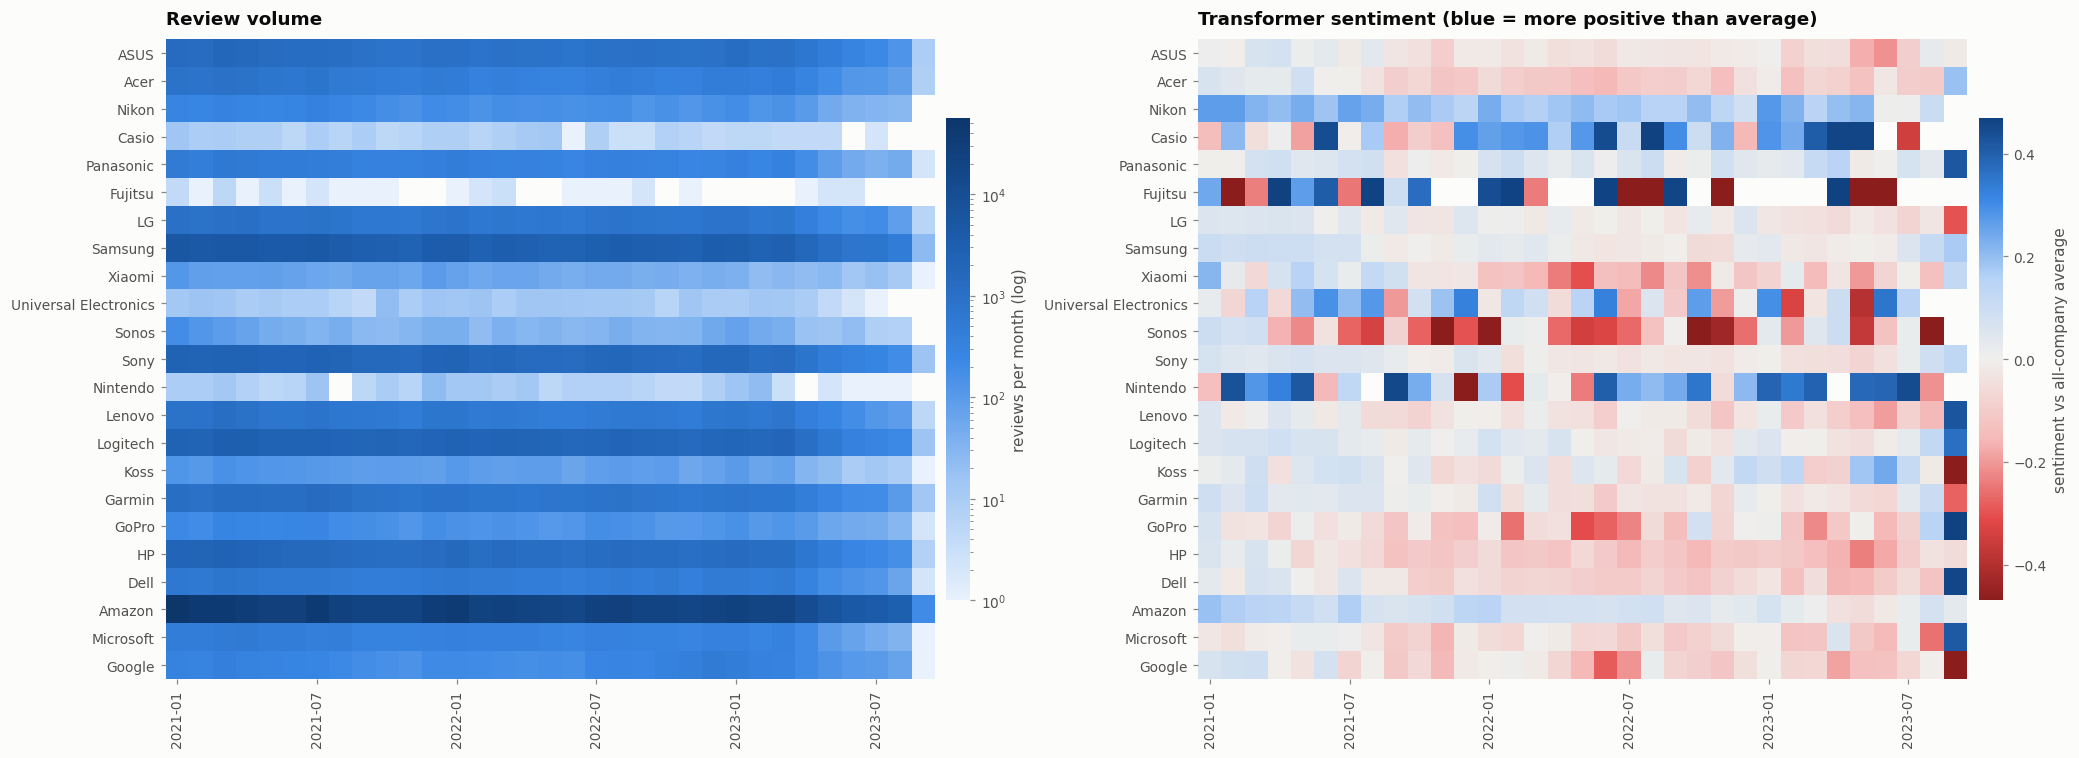

In [12]:
def ewm(a, halflife):
    return pd.DataFrame(a).ewm(halflife=halflife, adjust=False).mean().to_numpy()

def ewm_ratio(num, den, halflife):
    n_, d_ = ewm(num, halflife), ewm(den, halflife)
    out = np.full_like(n_, np.nan)
    ok = d_ > 1e-8
    out[ok] = n_[ok] / d_[ok]
    return out

def lagdiff(a, k):
    out = np.full_like(a, np.nan)
    out[k:] = a[k:] - a[:-k]
    return out

def standardize_panel(F, fit_rows, skip=()):
    F = F.astype(np.float64)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        mu, sd = np.nanmean(F[fit_rows], axis=0), np.nanstd(F[fit_rows], axis=0)
    mu = np.where(np.isfinite(mu), mu, 0.0)
    sd = np.where(np.isfinite(sd) & (sd > 1e-8), sd, 1.0)
    for j in skip:
        mu[:, j], sd[:, j] = 0.0, 1.0
    Z = np.nan_to_num((F - mu) / sd, nan=0.0, posinf=0.0, neginf=0.0)
    return np.clip(Z, -5, 5).astype(np.float32), mu, sd

def windows(F, ts, L):
    sw = np.lib.stride_tricks.sliding_window_view(F, L, axis=0)           # (T-L+1, N, F, L)
    return np.ascontiguousarray(sw[np.asarray(ts) - L + 1].transpose(0, 1, 3, 2), dtype=np.float32)

rs = reviews.loc[score_idx, ["date", "company", "rating"]].join(review_scores[["sentiment", "neg_share"]])
node_of_review = rs["company"].map(NODE_ID).to_numpy(dtype=float)
date_ns = rs["date"].to_numpy().astype("datetime64[ns]").astype(np.int64)

# ---- daily review panel (stock task) ----
day = np.searchsorted(CAL.to_numpy().astype("datetime64[ns]").astype(np.int64), date_ns, side="right")
ok = (day < T) & np.isfinite(node_of_review)
d_i, n_i = day[ok], node_of_review[ok].astype(int)
cnt = np.zeros((T, N)); sent_sum = np.zeros((T, N)); star_sum = np.zeros((T, N)); neg_sum = np.zeros((T, N))
np.add.at(cnt, (d_i, n_i), 1.0)
np.add.at(sent_sum, (d_i, n_i), rs["sentiment"].to_numpy()[ok])
np.add.at(star_sum, (d_i, n_i), (rs["rating"].to_numpy()[ok] - 3.0) / 2.0)
np.add.at(neg_sum, (d_i, n_i), rs["neg_share"].to_numpy()[ok])
log_cnt = np.log1p(cnt)
REV_FEATS = ["log_reviews", "abnormal_volume", "sentiment_fast", "sentiment_slow", "stars_slow", "neg_share_slow"]
REV_RAW = np.stack([log_cnt, ewm(log_cnt, 5) - ewm(log_cnt, 60), ewm_ratio(sent_sum, cnt, 5),
                    ewm_ratio(sent_sum, cnt, 20), ewm_ratio(star_sum, cnt, 20), ewm_ratio(neg_sum, cnt, 20)], axis=-1)

# ---- daily market panel ----
r1 = lagdiff(logp, 1)
lv = np.log1p(np.where(TRADED, VOLUME, np.nan))
MKT_FEATS = ["ret_1d", "ret_5d", "ret_20d", "vol_20d", "gap_ma50", "volume_shock", "traded"]
MKT_RAW = np.stack([
    r1, lagdiff(logp, 5), lagdiff(logp, 20),
    pd.DataFrame(r1).rolling(20, min_periods=10).std().to_numpy(),
    logp - np.log(pd.DataFrame(CLOSE).rolling(50, min_periods=20).mean().to_numpy()),
    lv - pd.DataFrame(lv).rolling(20, min_periods=5).mean().to_numpy(),
    TRADED.astype(float)], axis=-1)

def stock_targets(H):
    """Forward H-day log return per company (Asian listings start one close later when ALIGN_TIMEZONES)."""
    Y = np.full((T, N), np.nan)
    M = np.zeros((T, N), dtype=bool)
    t_idx = np.arange(T)
    for i in range(N):
        a = t_idx + OFFSET[i]
        b = a + H
        valid = b < T
        Y[valid, i] = logp[b[valid], i] - logp[a[valid], i]
        M[valid, i] = TRADED[b[valid], i]
    return Y, M & np.isfinite(Y)

# ---- weekly brand panel ----
wk = np.searchsorted(WEEKS.to_numpy().astype("datetime64[ns]").astype(np.int64), date_ns, side="left")
okw = (wk < W) & np.isfinite(node_of_review) & (rs["date"].to_numpy() > (WEEKS[0] - pd.Timedelta(days=7)).to_datetime64())
w_i, wn_i = wk[okw], node_of_review[okw].astype(int)
cw_ = np.zeros((W, N)); starw = np.zeros((W, N)); sentw = np.zeros((W, N)); negw = np.zeros((W, N))
np.add.at(cw_, (w_i, wn_i), 1.0)
np.add.at(starw, (w_i, wn_i), rs["rating"].to_numpy()[okw].astype(float))
np.add.at(sentw, (w_i, wn_i), rs["sentiment"].to_numpy()[okw])
np.add.at(negw, (w_i, wn_i), rs["neg_share"].to_numpy()[okw])

def rsum(a, k):
    return pd.DataFrame(a).rolling(k, min_periods=1).sum().to_numpy()

def ratio(num, den):
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / np.maximum(den, 1e-12), np.nan)

H_B = BRAND_HORIZON
c1, cH, c13, c52 = cw_, rsum(cw_, H_B), rsum(cw_, 13), rsum(cw_, 52)
n13 = np.minimum(np.arange(1, W + 1), 13)[:, None]   # weeks actually available so far
n52 = np.minimum(np.arange(1, W + 1), 52)[:, None]
sH, s13, s52 = ratio(rsum(starw, H_B), cH), ratio(rsum(starw, 13), c13), ratio(rsum(starw, 52), c52)
senH, sen13 = ratio(rsum(sentw, H_B), cH), ratio(rsum(sentw, 13), c13)
negH = ratio(rsum(negw, H_B), cH)
wk_pos = CAL.searchsorted(WEEKS, side="right") - 1                         # last trading day ≤ week end
lp_w = np.where((wk_pos >= 0)[:, None], logp[np.clip(wk_pos, 0, None)], np.nan)
vol_d = pd.DataFrame(r1).rolling(20, min_periods=10).std().to_numpy()
woy = WEEKS.isocalendar()["week"].to_numpy(dtype=float)
season = np.stack([np.sin(2 * np.pi * woy / 52.18), np.cos(2 * np.pi * woy / 52.18)], -1)

BRAND_FEATS = ["log_count_1w", "log_vol_4w", "log_vol_13w", "log_vol_52w", "stars_4w", "stars_13w", "stars_52w",
               "sentiment_4w", "sentiment_13w", "neg_share_4w", "text_minus_stars_13w",
               "season_sin", "season_cos", "stock_ret_1w", "stock_ret_4w", "stock_vol_4w"]
BR_RAW = np.stack([
    np.log1p(c1), np.log1p(cH / H_B), np.log1p(c13 / n13), np.log1p(c52 / n52), sH, s13, s52, senH, sen13, negH,
    sen13 - (s13 - 3.0) / 2.0,
    np.repeat(season[:, None, 0], N, 1), np.repeat(season[:, None, 1], N, 1),
    lagdiff(lp_w, 1), lagdiff(lp_w, 4),
    np.where((wk_pos >= 0)[:, None], vol_d[np.clip(wk_pos, 0, None)], np.nan) * np.sqrt(5)], axis=-1)
REVIEW_IDX = list(range(0, 13))                      # review history + seasonality → GNN "review" stream
MARKET_IDX = [13, 14, 15]                           # brand's own stock → GNN "market" stream
SEASON_IDX = (11, 12)

# targets: change over the next H_B weeks vs the last H_B weeks
fut = lambda a: np.vstack([a[H_B:], np.full((H_B,) + a.shape[1:], np.nan)])
Y_VOL = fut(np.log1p(cH / H_B)) - np.log1p(cH / H_B)
Y_STAR = fut(sH) - sH
M_VOL = np.isfinite(Y_VOL) & (c52 >= 13)
M_STAR = np.isfinite(Y_STAR) & (cH >= MIN_REVIEWS_FOR_STARS) & (fut(cH) >= MIN_REVIEWS_FOR_STARS)
# baselines (all use past data only)
BASE_VOL = {"Persistence": np.zeros((W, N)),
            "Long-run average": np.log1p(c52 / n52) - np.log1p(cH / H_B),
            "Same period last year": np.vstack([np.full((52, N), np.nan), Y_VOL[:-52]])}
BASE_STAR = {"Persistence": np.zeros((W, N)), "Long-run average": s52 - sH}
print(f"Daily review panel {REV_RAW.shape} | daily market panel {MKT_RAW.shape} | weekly brand panel {BR_RAW.shape}")
print(f"Brand targets: volume change on {int(M_VOL.sum()):,} brand-weeks, star change on {int(M_STAR.sum()):,}")

# Figure 6: review volume and sentiment per company and month (brand window)
rsm = rs[(rs["date"] >= BRAND_WIN[0]) & (rs["date"] <= BRAND_WIN[1])].copy()
rsm["month"] = rsm["date"].dt.to_period("M")
months = pd.period_range(BRAND_WIN[0], BRAND_WIN[1], freq="M")
vol_m = rsm.groupby(["company", "month"]).size().unstack().reindex(index=NODES, columns=months)
sen_m = rsm.groupby(["company", "month"])["sentiment"].mean().unstack().reindex(index=NODES, columns=months)
sen_rel = sen_m - np.nanmean(sen_m.to_numpy(dtype=float))
lim = float(np.nanpercentile(np.abs(sen_rel.to_numpy(dtype=float)), 98)) if np.isfinite(sen_rel.to_numpy(dtype=float)).any() else 1.0
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
vm = vol_m.to_numpy(dtype=float)
heatmap(axes[0], np.where(vm > 0, vm, np.nan), NODES, [str(m) for m in months], SEQ,
        norm=LogNorm(vmin=1, vmax=max(2, np.nanmax(vm))), cbar_label="reviews per month (log)", xtick_step=6)
axes[0].set_title("Review volume")
heatmap(axes[1], sen_rel.to_numpy(dtype=float), NODES, [str(m) for m in months], DIV,
        norm=TwoSlopeNorm(0, -lim, lim), cbar_label="sentiment vs all-company average", xtick_step=6)
axes[1].set_title("Transformer sentiment (blue = more positive than average)")
fig.tight_layout()
savefig(fig, "06_review_features")

stock graph: return correlation 40 edges, industry 64 edges
brand graph: return correlation 39 edges, industry 64 edges


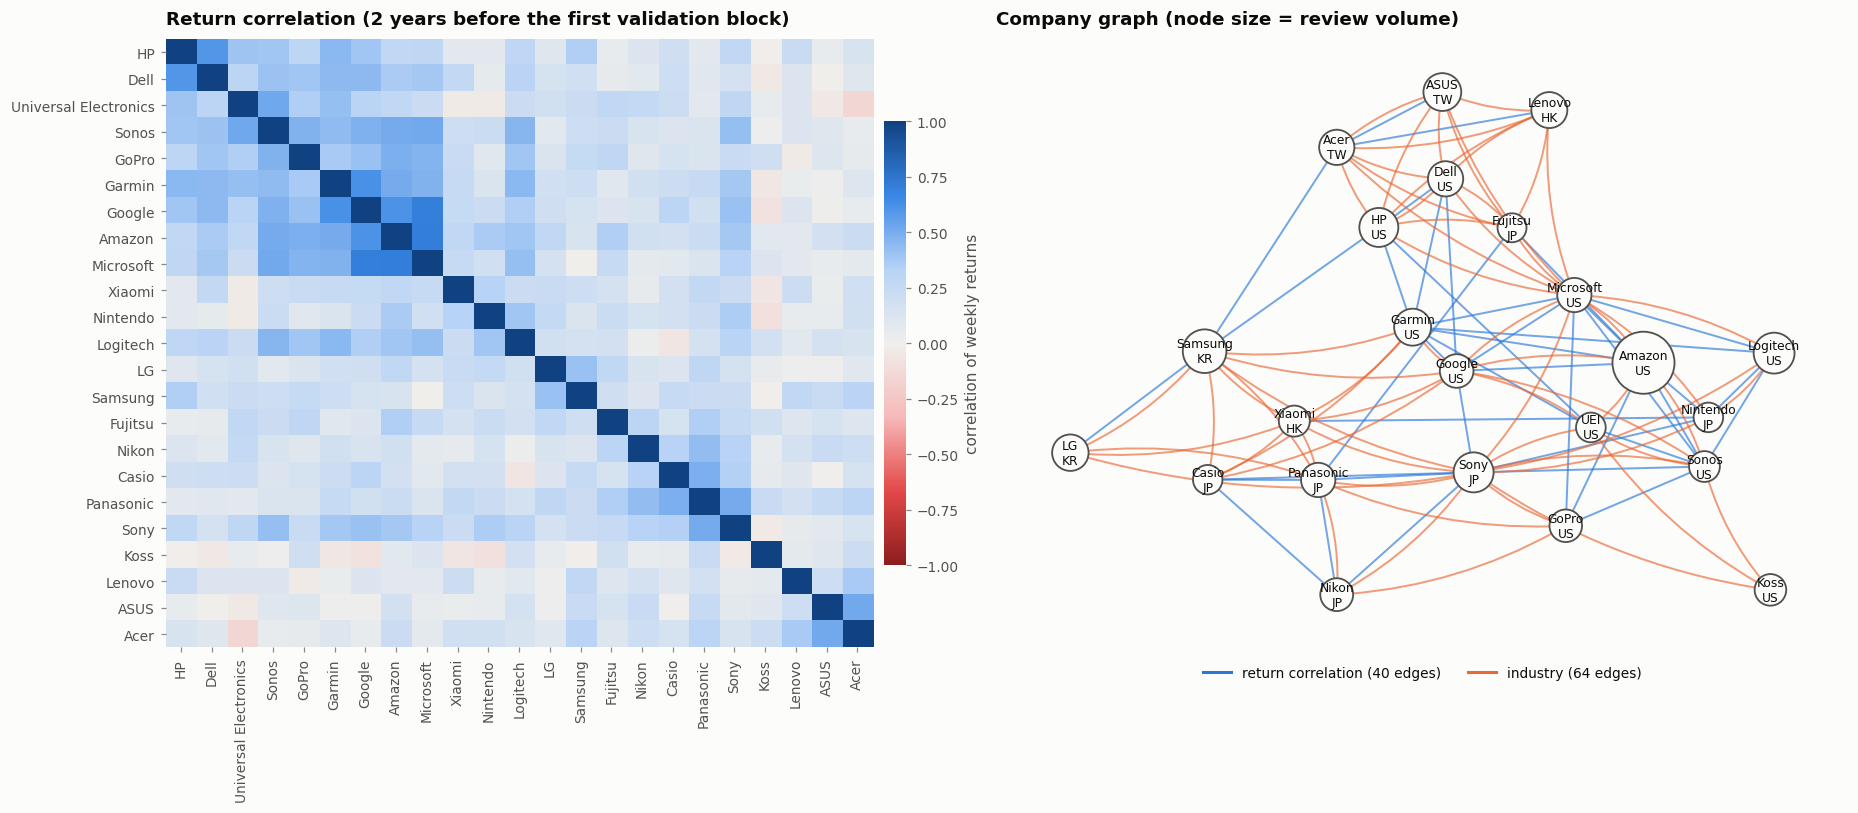

In [13]:
def topk_symmetric(S, k, min_value, extra_ok=None):
    S = np.array(S, dtype=float)
    np.fill_diagonal(S, -np.inf)
    A = np.zeros_like(S)
    for i in range(len(S)):
        for j in np.argsort(-S[i])[:k]:
            if np.isfinite(S[i, j]) and S[i, j] >= min_value and (extra_ok is None or extra_ok[i, j]):
                A[i, j] = S[i, j]
    return np.maximum(A, A.T)

def build_graph(cutoff):
    rows = np.where((CAL < cutoff) & (CAL >= cutoff - pd.Timedelta(days=730)))[0]
    wkly = CLOSE[rows][::5]
    corr = np.nan_to_num(pd.DataFrame(np.diff(np.log(wkly), axis=0)).corr(min_periods=20).to_numpy())
    rel = {"return correlation": topk_symmetric(corr, CORR_TOP_K, CORR_MIN)}
    A = np.zeros((N, N))
    for members in INDUSTRY_GROUPS.values():
        ids = [NODE_ID[m] for m in members if m in NODE_ID]
        for a in ids:
            for b in ids:
                if a != b:
                    A[a, b] = 1.0
    rel["industry"] = A
    if USER_COL is not None and USER_COL in reviews.columns:
        ur = reviews.loc[(reviews["date"] < cutoff) & reviews["company"].isin(NODES), [USER_COL, "company"]]
        sets = ur.dropna().drop_duplicates().groupby("company")[USER_COL].apply(set).to_dict()
        J, SH = np.zeros((N, N)), np.zeros((N, N))
        for a in range(N):
            for b in range(a + 1, N):
                sa, sb = sets.get(NODES[a], set()), sets.get(NODES[b], set())
                inter = len(sa & sb)
                if inter:
                    SH[a, b] = SH[b, a] = inter
                    J[a, b] = J[b, a] = inter / len(sa | sb)
        Aco = topk_symmetric(J, COREVIEW_TOP_K, 1e-12, extra_ok=SH >= COREVIEW_MIN_USERS)
        rel["shared reviewers"] = Aco / Aco.max() if Aco.max() > 0 else Aco
    rel = {k: v for k, v in rel.items() if v.max() > 0}
    adj = np.stack(list(rel.values())).astype(np.float32)
    union = (adj > 0).sum(0).astype(float)
    w_norm = union / np.maximum(union.sum(1, keepdims=True), 1)       # row-normalised, for neighbour-mean features
    return dict(relations=rel, adj=adj, w_norm=w_norm, corr=corr)

G_STOCK = build_graph(CAL[STOCK_FOLDS[0]["val"][0]])
G_BRAND = build_graph(WEEKS[BRAND_FOLDS[0]["val"][0]] - pd.Timedelta(days=6))
for name, Gr in (("stock", G_STOCK), ("brand", G_BRAND)):
    print(f"{name} graph: " + ", ".join(f"{k} {int((v > 0).sum() // 2)} edges" for k, v in Gr["relations"].items()))

# Figure 7
CORR = G_STOCK["corr"]
order = leaves_list(linkage(1 - CORR[np.triu_indices(N, 1)], method="average"))
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw=dict(width_ratios=[1, 1.15]))
heatmap(axes[0], CORR[np.ix_(order, order)], [NODES[i] for i in order], [NODES[i] for i in order], DIV,
        vmin=-1, vmax=1, cbar_label="correlation of weekly returns")
axes[0].set_title("Return correlation (2 years before the first validation block)")
ax = axes[1]
G = nx.Graph()
G.add_nodes_from(range(N))
for A in G_STOCK["relations"].values():
    for a, b in zip(*np.nonzero(np.triu(A, 1))):
        G.add_edge(int(a), int(b), weight=G[a][b]["weight"] + 1 if G.has_edge(a, b) else 1)
pos = nx.spring_layout(G, seed=SEED, k=1.6 / np.sqrt(N), iterations=300, weight="weight")
handles = []
for r, (name, A) in enumerate(G_STOCK["relations"].items()):
    edges = [(int(a), int(b)) for a, b in zip(*np.nonzero(np.triu(A, 1)))]
    nx.draw_networkx_edges(G, pos, edgelist=edges, ax=ax, edge_color=SERIES[r], width=1.3, alpha=0.65,
                           arrows=True, arrowstyle="-", connectionstyle=f"arc3,rad={0.12 * r}")
    handles.append(Line2D([0], [0], color=SERIES[r], lw=2, label=f"{name} ({len(edges)} edges)"))
SHORT_NAME = {"Universal Electronics": "UEI"}
sizes = 350 + 1300 * np.sqrt(cnt.sum(0) / max(cnt.sum(0).max(), 1))
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes, node_color=SURFACE, edgecolors=INK2, linewidths=1.2)
nx.draw_networkx_labels(G, pos, ax=ax, labels={i: f"{SHORT_NAME.get(n, n)}\n{REGION[i]}" for i, n in enumerate(NODES)},
                        font_size=8, font_color=INK)
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=len(handles), fontsize=9)
ax.set_title("Company graph (node size = review volume)")
ax.axis("off")
fig.tight_layout()
savefig(fig, "07_company_graph")

In [14]:
@keras.saving.register_keras_serializable(package="rmgnn")
class NodeEmbedding(layers.Layer):
    def __init__(self, n_nodes, dim, **kwargs):
        super().__init__(**kwargs)
        self.n_nodes, self.dim = n_nodes, dim

    def build(self, input_shape):
        self.emb = self.add_weight(name="emb", shape=(self.n_nodes, self.dim),
                                   initializer=keras.initializers.RandomNormal(stddev=0.1))

    def call(self, x):
        return ops.zeros_like(x[..., :1]) + ops.expand_dims(self.emb, 0)

    def get_config(self):
        return {**super().get_config(), "n_nodes": self.n_nodes, "dim": self.dim}


@keras.saving.register_keras_serializable(package="rmgnn")
class RelationalGraphAttention(layers.Layer):
    """Multi-head attention over a fixed multi-relation graph + learned adjacency. (B,N,d) → (B,N,units), attn (B,H,N,N)."""
    def __init__(self, adjacency, units, heads=4, attn_dropout=0.1, adaptive_dim=8, **kwargs):
        super().__init__(**kwargs)
        adj = np.asarray(adjacency, dtype="float32")
        self.adjacency = adj[None] if adj.ndim == 2 else adj
        if units % heads:
            raise ValueError("units must be divisible by heads")
        self.units, self.heads, self.head_dim = units, heads, units // heads
        self.attn_dropout, self.adaptive_dim = attn_dropout, adaptive_dim
        self.drop = layers.Dropout(attn_dropout)

    def build(self, input_shape):
        d_in = int(input_shape[-1])
        R, N_ = self.adjacency.shape[0], self.adjacency.shape[1]
        H, Dh = self.heads, self.head_dim
        glorot, small = "glorot_uniform", keras.initializers.RandomNormal(stddev=0.1)
        self.W = self.add_weight(name="W", shape=(d_in, H * Dh), initializer=glorot)
        self.a_self = self.add_weight(name="a_self", shape=(H, Dh), initializer=glorot)
        self.a_nbr = self.add_weight(name="a_nbr", shape=(H, Dh), initializer=glorot)
        self.rel_scale = self.add_weight(name="rel_scale", shape=(R, H), initializer="ones")
        self.adj = self.add_weight(name="adj", shape=(R, N_, N_), initializer="zeros", trainable=False)
        self.adj.assign(self.adjacency)
        self.E1 = self.add_weight(name="E1", shape=(N_, self.adaptive_dim), initializer=small)
        self.E2 = self.add_weight(name="E2", shape=(N_, self.adaptive_dim), initializer=small)
        self.W_adapt = self.add_weight(name="W_adapt", shape=(d_in, self.units), initializer=glorot)
        self.gate_logit = self.add_weight(name="gate_logit", shape=(1,), initializer=keras.initializers.Constant(-1.0))
        self.W_root = self.add_weight(name="W_root", shape=(d_in, self.units), initializer=glorot)
        self.bias = self.add_weight(name="bias", shape=(self.units,), initializer="zeros")
        self.n_nodes = N_

    def adaptive_adjacency(self):
        return ops.softmax(ops.relu(ops.matmul(self.E1, ops.transpose(self.E2))), axis=-1)

    def call(self, h, training=None):
        N_, H, Dh = self.n_nodes, self.heads, self.head_dim
        z = ops.reshape(ops.matmul(h, self.W), (-1, N_, H, Dh))
        s_self = ops.einsum("bnhd,hd->bhn", z, self.a_self)
        s_nbr = ops.einsum("bnhd,hd->bhn", z, self.a_nbr)
        e = ops.leaky_relu(ops.expand_dims(s_self, -1) + ops.expand_dims(s_nbr, -2), negative_slope=0.2)
        e = e + ops.expand_dims(ops.einsum("rij,rh->hij", self.adj, self.rel_scale), 0)
        allowed = ops.cast(ops.greater(ops.sum(self.adj, axis=0) + ops.eye(N_), 0.0), "float32")
        e = e + (1.0 - allowed) * (-1e9)
        alpha = ops.softmax(e, axis=-1)
        msg = ops.reshape(ops.einsum("bhij,bjhd->bihd", self.drop(alpha, training=training), z), (-1, N_, H * Dh))
        adapt = ops.einsum("ij,bjd->bid", self.adaptive_adjacency(), ops.matmul(h, self.W_adapt))
        g = ops.sigmoid(self.gate_logit)
        out = (1.0 - g) * msg + g * adapt + ops.matmul(h, self.W_root) + self.bias
        return ops.elu(out), alpha

    def get_config(self):
        return {**super().get_config(), "adjacency": self.adjacency.tolist(), "units": self.units,
                "heads": self.heads, "attn_dropout": self.attn_dropout, "adaptive_dim": self.adaptive_dim}


def masked_huber(y_true, y_pred, delta=1.0):
    y, m = y_true[..., :1], y_true[..., 1:2]
    err = ops.abs(y - y_pred)
    quad = ops.minimum(err, delta)
    return ops.sum((0.5 * ops.square(quad) + delta * (err - quad)) * m) / (ops.sum(m) + 1e-6)

def masked_bce(y_true, y_pred):
    y, m = y_true[..., :1], y_true[..., 1:2]
    p = ops.clip(y_pred, 1e-6, 1.0 - 1e-6)
    return ops.sum(-(y * ops.log(p) + (1.0 - y) * ops.log(1.0 - p)) * m) / (ops.sum(m) + 1e-6)


def build_gnn(streams, heads, adjacency, lookback, hp=None, seed=0, use_graph=True):
    """streams: {input name: n_features} (first = primary, the rest are gated); heads: {name: ("reg"|"cls", weight)}."""
    hp = {**HP, **(hp or {})}
    keras.utils.set_random_seed(seed)
    inputs, enc = {}, {}
    for s, (name, nf) in enumerate(streams.items()):
        units = hp["price_units"] if s == 0 else hp["review_units"]
        inputs[name] = keras.Input(shape=(N, lookback, nf), name=name)
        e = layers.LSTM(units, name=f"{name}_lstm")(ops.reshape(inputs[name], (-1, lookback, nf)))
        enc[name] = ops.reshape(e, (-1, N, units))
    names = list(streams)
    h, gates = enc[names[0]], {}
    for name in names[1:]:
        g = layers.Dense(enc[name].shape[-1], activation="sigmoid", name=f"gate_{name}")(
            layers.Concatenate()([enc[names[0]], enc[name]]))
        gates[f"gate_{name}"] = g
        h = layers.Concatenate()([h, layers.Multiply()([g, enc[name]])])
    h = layers.Dense(hp["hidden"], activation="gelu", name="fuse")(h)
    h = layers.Concatenate()([h, NodeEmbedding(N, 8, name="company_embedding")(h)])
    h = layers.Dropout(hp["dropout"])(layers.Dense(hp["hidden"], activation="gelu")(h))
    h_local, attn = h, {}
    for l in range(hp["gnn_layers"]):
        if use_graph:
            m, a = RelationalGraphAttention(adjacency, hp["hidden"], heads=hp["heads"], name=f"rgat_{l}")(h)
            attn[f"attn_{l}"] = a
        else:
            m = layers.Dense(hp["hidden"], activation="elu", name=f"node_mlp_{l}")(h)
        h = layers.LayerNormalization(name=f"ln_{l}")(layers.Add()([h, layers.Dropout(hp["dropout"])(m)]))
    z = layers.Dropout(hp["dropout"])(layers.Dense(32, activation="gelu")(layers.Concatenate()([h_local, h])))
    outputs = {name: layers.Dense(1, activation="sigmoid" if kind == "cls" else None, name=name)(z)
               for name, (kind, _) in heads.items()}
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.AdamW(hp["lr"], weight_decay=hp["weight_decay"], clipnorm=1.0),
                  loss={n: masked_bce if k == "cls" else masked_huber for n, (k, _) in heads.items()},
                  loss_weights={n: w for n, (_, w) in heads.items()})
    explain = {**gates, **attn}
    return model, (keras.Model(inputs, explain) if explain else None)


def train_gnn(streams, heads, adjacency, data, lookback, seed, hp=None, use_graph=True):
    """data: {"train"|"val"|"test": {"x": {stream: array}, "y": {head: array}}} → predictions per split and head."""
    hp = {**HP, **(hp or {})}
    model, explainer = build_gnn(streams, heads, adjacency, lookback, hp, seed, use_graph)
    xs = lambda split: {k: data[split]["x"][k] for k in streams}
    ys = lambda split: {k: data[split]["y"][k] for k in heads}
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=GNN_PATIENCE, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)]
    hist = model.fit(xs("train"), ys("train"), validation_data=(xs("val"), ys("val")), epochs=GNN_EPOCHS,
                     batch_size=GNN_BATCH, shuffle=True, verbose=0, callbacks=callbacks)
    out = dict(history={k: [float(v) for v in vals] for k, vals in hist.history.items()},
               best_val_loss=float(np.min(hist.history["val_loss"])), model=model)
    for split in ("val", "test"):
        p = model.predict(xs(split), batch_size=256, verbose=0)
        out[f"pred_{split}"] = {k: np.asarray(p[k])[..., 0] for k in heads}
    if explainer is not None:
        e = explainer.predict(xs("test"), batch_size=256, verbose=0)
        out["explain"] = {k: np.asarray(v) for k, v in e.items()}
    return out

In [15]:
_m, _ = build_gnn({"price": len(MKT_FEATS), "review": len(REV_FEATS)}, {"ret": ("reg", 1.0), "dir": ("cls", 0.3)},
                  G_STOCK["adj"], LOOKBACK)
_m.summary()
print(f"Stock GNN trainable parameters: {_m.count_params():,}")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ price (InputLayer)  │ (None, 23, 40, 7) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ review (InputLayer) │ (None, 23, 40, 6) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 40, 7)     │          0 │ price[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 40, 6)     │          0 │ review[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ price_lstm (LSTM)   │ (None, 32)        │      5,120 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ review_lstm (LSTM)  │ (None, 16)        │      1,472 │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 23, 32)    │          0 │ price_lstm[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 23, 16)    │          0 │ review_lstm[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 23, 48)    │          0 │ reshape_1[0][0],  │
│ (Concatenate)       │                   │            │ reshape_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gate_review (Dense) │ (None, 23, 16)    │        784 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 23, 16)    │          0 │ gate_review[0][0… │
│                     │                   │            │ reshape_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 23, 48)    │          0 │ reshape_1[0][0],  │
│ (Concatenate)       │                   │            │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fuse (Dense)        │ (None, 23, 32)    │      1,568 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ company_embedding   │ (None, 23, 8)     │        184 │ fuse[0][0]        │
│ (NodeEmbedding)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 23, 40)    │          0 │ fuse[0][0],       │
│ (Concatenate)       │                   │            │ company_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 23, 32)    │      1,312 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 23, 32)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rgat_0              │ [(None, 23, 32),  │      4,603 │ dropout[0][0]     │
│ (RelationalGraphAt… │ (None, 4, 23,     │            │                   │
│                     │ 23)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 23, 32)    │          0 │ rgat_0[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 23, 32)    │          0 │ dropout[0][0],    │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ln_0                │ (None, 23, 32)    │         64 │ add[0][0]       

 Total params: 21,920 (85.62 KB)

 Trainable params: 19,804 (77.36 KB)

 Non-trainable params: 2,116 (8.27 KB)

Stock GNN trainable parameters: 21,920


In [16]:
# ---- LightGBM + metric helpers ------------------------------------------------------------------------------
LGB_BASE = dict(n_estimators=3000, learning_rate=0.03, num_leaves=15, min_child_samples=50, subsample=0.8,
                subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, n_jobs=-1)

def fit_lgbm(kind, Xtr, ytr, Xva, yva, params=None, seed=SEED):
    p = {**LGB_BASE, **(params or {}), "random_state": seed}
    if kind == "reg":
        model = lgb.LGBMRegressor(objective="huber", alpha=1.0, **p)
    else:
        model = lgb.LGBMClassifier(objective="binary", **p)
    model.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

def lgbm_val_loss(model, X, y):
    if isinstance(model, lgb.LGBMClassifier):
        p = np.clip(model.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
        return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
    e = np.abs(model.predict(X) - y)
    return float(np.mean(np.where(e < 1, 0.5 * e ** 2, e - 0.5)))

def rank_ic(a, b):
    if len(a) < 5:
        return np.nan
    ra, rb = rankdata(a), rankdata(b)
    if ra.std() == 0 or rb.std() == 0:
        return np.nan
    return float(np.corrcoef(ra, rb)[0, 1])

def daily_ic(score, raw, mask):
    out = np.full(len(raw), np.nan)
    for s in range(len(raw)):
        ok = mask[s] & np.isfinite(score[s])
        out[s] = rank_ic(score[s][ok], raw[s][ok])
    return out

def long_short(score, raw, mask, dates, H, k=TOP_K_BACKTEST):
    rows = []
    for s in range(0, len(raw), H):
        idx = np.where(mask[s] & np.isfinite(score[s]))[0]
        if len(idx) < 2 * k:
            continue
        order = idx[np.argsort(score[s, idx], kind="stable")]
        simple = np.expm1(raw[s])
        rows.append((dates[s], simple[order[-k:]].mean() - simple[order[:k]].mean(), simple[idx].mean()))
    return pd.DataFrame(rows, columns=["date", "long_short", "equal_weight"]).set_index("date")

def sharpe(r, H):
    r = np.asarray(r, dtype=float)
    return float(r.mean() / r.std(ddof=1) * np.sqrt(252 / H)) if len(r) > 2 and r.std(ddof=1) > 0 else np.nan

def stock_eval(score, prob, raw, mask, dates, H, dir_pred=None):
    up = raw > 0
    if dir_pred is None:
        dir_pred = (prob > 0.5) if prob is not None else (score > 0)
    auc_in = prob if prob is not None else score
    ok = mask & np.isfinite(auc_in)
    try:
        auc = float(roc_auc_score(up[ok], auc_in[ok]))
    except ValueError:
        auc = np.nan
    ics = daily_ic(score, raw, mask)
    icv = ics[np.isfinite(ics)]
    ic_t = float(icv.mean() / icv.std(ddof=1) * np.sqrt(len(icv) / H)) if len(icv) > 2 and icv.std(ddof=1) > 0 else np.nan
    ls = long_short(score, raw, mask, dates, H)
    return dict(dir_acc=float(np.mean(dir_pred[mask] == up[mask])), auc=auc,
                ic=float(icv.mean()) if len(icv) else np.nan, ic_t=ic_t,
                ls_sharpe=sharpe(ls["long_short"], H) if len(ls) else np.nan, _ics=ics, _ls=ls)

def cs_rank(a, mask):
    """Cross-sectional rank in [0, 1] per row (masked entries → NaN)."""
    out = np.full(a.shape, np.nan)
    for s in range(len(a)):
        ok = mask[s] & np.isfinite(a[s])
        if ok.sum() > 1:
            out[s, ok] = (rankdata(a[s, ok]) - 1) / (ok.sum() - 1)
    return out

In [17]:
STOCK_HEADS = {"ret": ("reg", 1.0), "dir": ("cls", 0.3)}
STOCK_STREAMS = {"GNN (price)": {"price": len(MKT_FEATS)},
                 "GNN (price + reviews)": {"price": len(MKT_FEATS), "review": len(REV_FEATS)}}
STOCK_MODELS = ["LightGBM (price)", "LightGBM (price + reviews)", "GNN (price)", "GNN (price + reviews)", "Ensemble"]
MODEL_COLOR = {"Ensemble": SERIES[0], "GNN (price + reviews)": SERIES[1], "LightGBM (price + reviews)": SERIES[2],
               "GNN (price)": SERIES[3], "LightGBM (price)": SERIES[4], "GNN": SERIES[1], "LightGBM": SERIES[2],
               "Long-run average": MUTED, "Same period last year": MUTED, "Persistence": MUTED}

def stock_flat(Xm, Xr, ts, use_reviews):
    A = Xm[ts]
    parts, names = [A], list(MKT_FEATS)
    parts.append(np.einsum("ij,sjf->sif", G_STOCK["w_norm"], A[..., [1, 2]]))
    names += ["nbr_ret_5d", "nbr_ret_20d"]
    parts.append(np.stack([rankdata(A[..., j], axis=1) / N for j in (1, 2)], -1))
    names += ["rank_ret_5d", "rank_ret_20d"]
    if use_reviews:
        R = Xr[ts]
        parts += [R, np.einsum("ij,sjf->sif", G_STOCK["w_norm"], R[..., [2, 1]]), (rankdata(R[..., 3], axis=1) / N)[..., None]]
        names += REV_FEATS + ["nbr_sentiment_fast", "nbr_abnormal_volume", "rank_sentiment_slow"]
    parts.append(np.broadcast_to(np.arange(N, dtype=float), A.shape[:2])[..., None])
    names += ["company_id"]
    F = np.concatenate(parts, -1)
    return F.reshape(-1, F.shape[-1]), names

def stock_fold(fold, H, Y_RAW, MASK):
    fit_rows = np.arange(STOCK_T[0], fold["train"][-1] + 1)
    Xm, _, _ = standardize_panel(MKT_RAW, fit_rows, skip=(6,))
    Xr, _, _ = standardize_panel(REV_RAW, fit_rows)
    tr = fold["train"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        yt = np.where(MASK[tr], Y_RAW[tr], np.nan)
        mu, sd = np.nanmean(yt, 0), np.nanstd(yt, 0)
    mu = np.where(np.isfinite(mu), mu, 0.0)
    sd = np.where(np.isfinite(sd) & (sd > 1e-8), sd, 1.0)
    Ystd = (Y_RAW - mu) / sd

    def split(ts):
        m = MASK[ts]
        fp, np_ = stock_flat(Xm, Xr, ts, False)
        ff, nf = stock_flat(Xm, Xr, ts, True)
        return dict(t=ts, x={"price": windows(Xm, ts, LOOKBACK), "review": windows(Xr, ts, LOOKBACK)},
                    y={"ret": np.stack([np.nan_to_num(Ystd[ts]), m], -1).astype(np.float32),
                       "dir": np.stack([Y_RAW[ts] > 0, m], -1).astype(np.float32)},
                    raw=Y_RAW[ts], mask=m, ystd=np.nan_to_num(Ystd[ts]), up=(Y_RAW[ts] > 0).astype(int),
                    flat={"price": fp, "full": ff}, names={"price": np_, "full": nf})
    return dict(mu=mu, sd=sd, train=split(tr), val=split(fold["val"]), test=split(fold["test"]))

def fit_lgbm_stock(D, variant, params=None):
    def xy(split, kind):
        m = D[split]["mask"].ravel()
        y = (D[split]["ystd"] if kind == "reg" else D[split]["up"]).ravel()[m]
        return D[split]["flat"][variant][m], y
    reg = fit_lgbm("reg", *xy("train", "reg"), *xy("val", "reg"), params)
    clf = fit_lgbm("cls", *xy("train", "cls"), *xy("val", "cls"), params)

    def predict(split):
        X, shape = D[split]["flat"][variant], D[split]["raw"].shape
        return reg.predict(X).reshape(shape), clf.predict_proba(X)[:, 1].reshape(shape)
    val_loss = lgbm_val_loss(reg, *xy("val", "reg")) + 0.3 * lgbm_val_loss(clf, *xy("val", "cls"))
    return dict(reg=reg, clf=clf, predict=predict, val_loss=val_loss)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  H= 1: validation IC +0.0715 (t +2.68) | AUC 0.5445


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  H= 5: validation IC +0.0622 (t +0.90) | AUC 0.5703


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  H=10: validation IC +0.0917 (t +1.12) | AUC 0.5902


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  H=20: validation IC +0.0848 (t +0.84) | AUC 0.6548
Selected horizon: 10 trading days


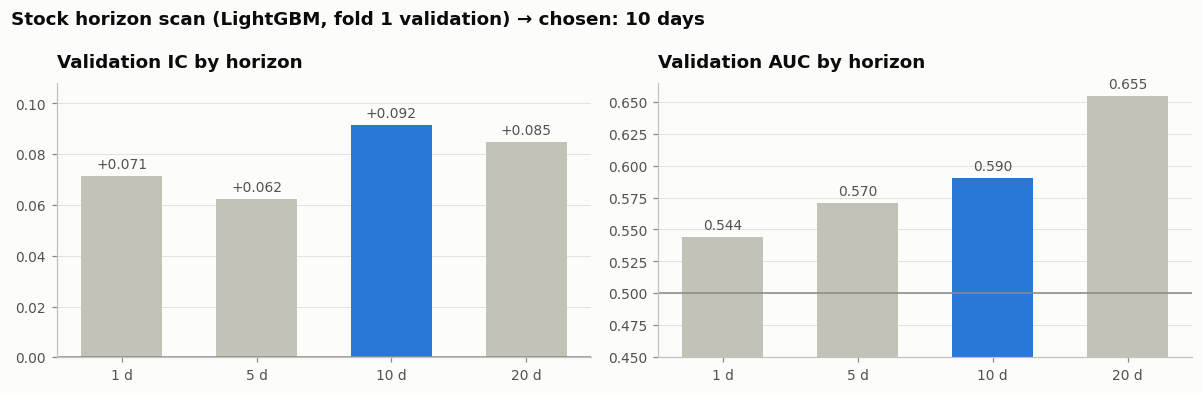

In [18]:
# ---- 9a. Horizon scan: which forecast horizon carries the most signal? (fold 1 validation only) ----------
if AUTO_HORIZON:
    scan = []
    for H in HORIZON_CANDIDATES:
        Y_, M_ = stock_targets(H)
        D_ = stock_fold(STOCK_FOLDS[0], H, Y_, M_)
        L_ = fit_lgbm_stock(D_, "full")
        sc, pr = L_["predict"]("val")
        ev_ = stock_eval(sc, pr, D_["val"]["raw"], D_["val"]["mask"], CAL[D_["val"]["t"]], H)
        scan.append(dict(H=H, val_IC=ev_["ic"], val_AUC=ev_["auc"], val_IC_t=ev_["ic_t"]))
        print(f"  H={H:>2}: validation IC {ev_['ic']:+.4f} (t {ev_['ic_t']:+.2f}) | AUC {ev_['auc']:.4f}")
    SCAN = pd.DataFrame(scan)
    HORIZON = int(SCAN.loc[SCAN["val_IC"].idxmax(), "H"])
    print(f"Selected horizon: {HORIZON} trading days")

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, col, title, fmt in ((axes[0], "val_IC", "Validation IC by horizon", "{:+.3f}"),
                                (axes[1], "val_AUC", "Validation AUC by horizon", "{:.3f}")):
        colors = [SERIES[0] if h == HORIZON else AXIS for h in SCAN["H"]]
        ax.bar([f"{h} d" for h in SCAN["H"]], SCAN[col], color=colors, width=0.6)
        for i, v in enumerate(SCAN[col]):
            ax.annotate(fmt.format(v), (i, v), xytext=(0, 3 if v >= 0 else -3), textcoords="offset points",
                        ha="center", va="bottom" if v >= 0 else "top", fontsize=9, color=INK2)
        ax.axhline(0 if col == "val_IC" else 0.5, color=MUTED, lw=1)
        ax.margins(y=0.18)
        if col == "val_AUC":
            ax.set_ylim(min(0.45, SCAN[col].min() - 0.01), max(0.55, SCAN[col].max() + 0.01))
        ax.set_title(title)
        ax.grid(axis="x", visible=False)
    fig.suptitle(f"Stock horizon scan (LightGBM, fold 1 validation) → chosen: {HORIZON} days", x=0.01, ha="left",
                 fontsize=12, fontweight="bold")
    fig.tight_layout()
    savefig(fig, "08_stock_horizon_scan")

Y_RAW, MASK = stock_targets(HORIZON)
MOM = lagdiff(logp, HORIZON)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils

  GNN {'hidden': 16, 'dropout': 0.15} → val loss 0.6427
  GNN {'hidden': 16, 'dropout': 0.35} → val loss 0.6402


  GNN {'hidden': 32, 'dropout': 0.15} → val loss 0.6814
  GNN {'hidden': 32, 'dropout': 0.35} → val loss 0.6560
  GNN {'hidden': 64, 'dropout': 0.15} → val loss 0.6399
  GNN {'hidden': 64, 'dropout': 0.35} → val loss 0.6287
Selected LightGBM: {'num_leaves': 7, 'min_child_samples': 30} | selected GNN: {'hidden': 64, 'dropout': 0.35}


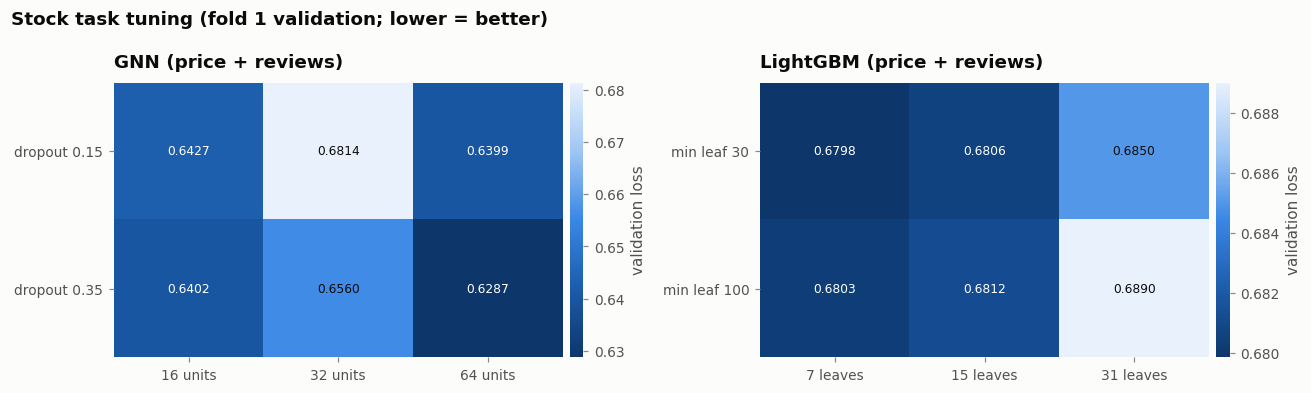

In [19]:
# ---- 9b. Tuning on fold 1 validation (GNN width × dropout, LightGBM leaves × min leaf size) --------------
D1 = stock_fold(STOCK_FOLDS[0], HORIZON, Y_RAW, MASK)
lgb_rows = []
for g in LGB_GRID:
    lgb_rows.append({**g, "val_loss": fit_lgbm_stock(D1, "full", g)["val_loss"]})
LGB_TUNE = pd.DataFrame(lgb_rows).sort_values("val_loss").reset_index(drop=True)
BEST_LGB_STOCK = {k: int(LGB_TUNE.iloc[0][k]) for k in ("num_leaves", "min_child_samples")}
gnn_rows = []
for g in GNN_GRID:
    r = train_gnn(STOCK_STREAMS["GNN (price + reviews)"], STOCK_HEADS, G_STOCK["adj"], D1, LOOKBACK, seed=SEED, hp=g)
    gnn_rows.append({**g, "val_loss": r["best_val_loss"], "epochs": len(r["history"]["loss"])})
    print(f"  GNN {g} → val loss {r['best_val_loss']:.4f}")
    del r
GNN_TUNE = pd.DataFrame(gnn_rows).sort_values("val_loss").reset_index(drop=True)
BEST_HP_STOCK = {"hidden": int(GNN_TUNE.iloc[0]["hidden"]), "dropout": float(GNN_TUNE.iloc[0]["dropout"])}
keras.backend.clear_session()
print("Selected LightGBM:", BEST_LGB_STOCK, "| selected GNN:", BEST_HP_STOCK)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
piv = GNN_TUNE.pivot(index="dropout", columns="hidden", values="val_loss").sort_index()
heatmap(axes[0], piv.to_numpy(), [f"dropout {d}" for d in piv.index], [f"{h} units" for h in piv.columns],
        SEQ.reversed(), cbar_label="validation loss", xrot=0, annotate="{:.4f}")
axes[0].set_title("GNN (price + reviews)")
piv = LGB_TUNE.pivot(index="min_child_samples", columns="num_leaves", values="val_loss").sort_index()
heatmap(axes[1], piv.to_numpy(), [f"min leaf {d}" for d in piv.index], [f"{h} leaves" for h in piv.columns],
        SEQ.reversed(), cbar_label="validation loss", xrot=0, annotate="{:.4f}")
axes[1].set_title("LightGBM (price + reviews)")
fig.suptitle("Stock task tuning (fold 1 validation; lower = better)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "09_stock_tuning")

In [20]:
# ---- 9c. Walk-forward: retrain every model on each fold, predict the next test quarter -------------------
STOCK_PRED = {m: [] for m in STOCK_MODELS}
STOCK_DATA, STOCK_IMPORTANCE, STOCK_GATES, STOCK_HIST = [], [], [], []
for k, fold in enumerate(STOCK_FOLDS):
    t0 = time.time()
    D = D1 if k == 0 else stock_fold(fold, HORIZON, Y_RAW, MASK)
    te = D["test"]
    for variant, name in (("price", "LightGBM (price)"), ("full", "LightGBM (price + reviews)")):
        L = fit_lgbm_stock(D, variant, BEST_LGB_STOCK)
        sc, pr = L["predict"]("test")
        STOCK_PRED[name].append(dict(score=sc * D["sd"] + D["mu"], prob=pr))
        if variant == "full":
            STOCK_IMPORTANCE.append(pd.Series(L["reg"].booster_.feature_importance(importance_type="gain"),
                                              index=te["names"]["full"]))
    for name, streams in STOCK_STREAMS.items():
        runs = [train_gnn(streams, STOCK_HEADS, G_STOCK["adj"], D, LOOKBACK, seed=SEED + 100 * k + s, hp=BEST_HP_STOCK)
                for s in range(N_SEEDS)]
        STOCK_PRED[name].append(dict(score=np.mean([r["pred_test"]["ret"] for r in runs], 0) * D["sd"] + D["mu"],
                                     prob=np.mean([r["pred_test"]["dir"] for r in runs], 0)))
        if "review" in streams:
            STOCK_HIST.append([r["history"] for r in runs])
            STOCK_GATES.append(np.mean([r["explain"]["gate_review"].mean(axis=(0, 2)) for r in runs], 0))
        del runs
    keras.backend.clear_session()
    g_, l_ = STOCK_PRED["GNN (price + reviews)"][-1], STOCK_PRED["LightGBM (price + reviews)"][-1]
    STOCK_PRED["Ensemble"].append(dict(score=0.5 * (cs_rank(g_["score"], te["mask"]) + cs_rank(l_["score"], te["mask"])),
                                       prob=0.5 * (g_["prob"] + l_["prob"])))
    STOCK_DATA.append(dict(t=te["t"], raw=te["raw"], mask=te["mask"],
                           up_rate=float(np.mean(D["train"]["raw"][D["train"]["mask"]] > 0))))
    print(f"fold {k + 1}/{len(STOCK_FOLDS)} done in {time.time() - t0:.0f}s")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils

fold 1/4 done in 100s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils

fold 2/4 done in 86s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils

fold 3/4 done in 93s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils

fold 4/4 done in 98s


In [21]:
# ---- 9d. Results: pooled over all test quarters + per fold ---------------------------------------------------
P_T = np.concatenate([d["t"] for d in STOCK_DATA])
P_RAW = np.vstack([d["raw"] for d in STOCK_DATA])
P_MASK = np.vstack([d["mask"] for d in STOCK_DATA])
P_DATES = CAL[P_T]
STOCK_METRICS = ["dir_acc", "auc", "ic", "ic_t", "ls_sharpe"]

def pooled(name, key):
    return np.vstack([p[key] for p in STOCK_PRED[name]])

STOCK_RES = {m: stock_eval(pooled(m, "score"), pooled(m, "prob"), P_RAW, P_MASK, P_DATES, HORIZON) for m in STOCK_MODELS}
always = np.vstack([np.full(d["raw"].shape, d["up_rate"] > 0.5) for d in STOCK_DATA])
STOCK_BASE = {
    "Majority class": dict(dir_acc=float(np.mean(always[P_MASK] == (P_RAW > 0)[P_MASK])), auc=0.5, ic=np.nan,
                           ic_t=np.nan, ls_sharpe=np.nan),
    "Momentum": stock_eval(MOM[P_T], None, P_RAW, P_MASK, P_DATES, HORIZON, dir_pred=MOM[P_T] > 0),
}
fold_rows = []
for k, d in enumerate(STOCK_DATA):
    for m in STOCK_MODELS:
        e = stock_eval(STOCK_PRED[m][k]["score"], STOCK_PRED[m][k]["prob"], d["raw"], d["mask"], CAL[d["t"]], HORIZON)
        fold_rows.append({"model": m, "fold": k + 1, **{x: e[x] for x in STOCK_METRICS}})
STOCK_FOLD_DF = pd.DataFrame(fold_rows)
STOCK_TABLE = pd.DataFrame({m: {x: r[x] for x in STOCK_METRICS} for m, r in {**STOCK_RES, **STOCK_BASE}.items()}).T
MAJ_FOLD = np.array([np.mean((d["up_rate"] > 0.5) == (d["raw"] > 0)[d["mask"]]) for d in STOCK_DATA])
IC_FOLD = lambda m: STOCK_FOLD_DF.loc[STOCK_FOLD_DF["model"] == m, "ic"].to_numpy(dtype=float)
ACC_FOLD = lambda m: STOCK_FOLD_DF.loc[STOCK_FOLD_DF["model"] == m, "dir_acc"].to_numpy(dtype=float)
STOCK_TABLE["quarters acc > majority"] = [f"{int((ACC_FOLD(m) > MAJ_FOLD).sum())}/{len(STOCK_DATA)}"
                                          if m in STOCK_MODELS else "" for m in STOCK_TABLE.index]
STOCK_TABLE["quarters IC > 0"] = [f"{int((IC_FOLD(m) > 0).sum())}/{len(STOCK_DATA)}"
                                  if m in STOCK_MODELS else "" for m in STOCK_TABLE.index]
pd.set_option("display.float_format", "{:.4f}".format)
print(f"Stock task · horizon {HORIZON} days · pooled test {P_DATES[0].date()} → {P_DATES[-1].date()} "
      f"({len(P_T)} dates, {int(P_MASK.sum()):,} labelled company-days)\n")
print(STOCK_TABLE.to_string())

Stock task · horizon 10 days · pooled test 2022-09-27 → 2023-09-13 (252 dates, 5,522 labelled company-days)

                            dir_acc    auc      ic    ic_t  ls_sharpe quarters acc > majority quarters IC > 0
LightGBM (price)             0.5013 0.5479 -0.0002 -0.0031     0.5976                     4/4             2/4
LightGBM (price + reviews)   0.4560 0.5103  0.0223  0.4661     0.3444                     2/4             3/4
GNN (price)                  0.4531 0.4916 -0.0019 -0.0419     0.5582                     2/4             2/4
GNN (price + reviews)        0.4625 0.5127 -0.0070 -0.1397     0.6991                     3/4             3/4
Ensemble                     0.4562 0.5107  0.0129  0.2582     0.4032                     3/4             3/4
Majority class               0.4388 0.5000     NaN     NaN        NaN                                        
Momentum                     0.5150 0.5119 -0.0144 -0.2801    -0.2085                                        


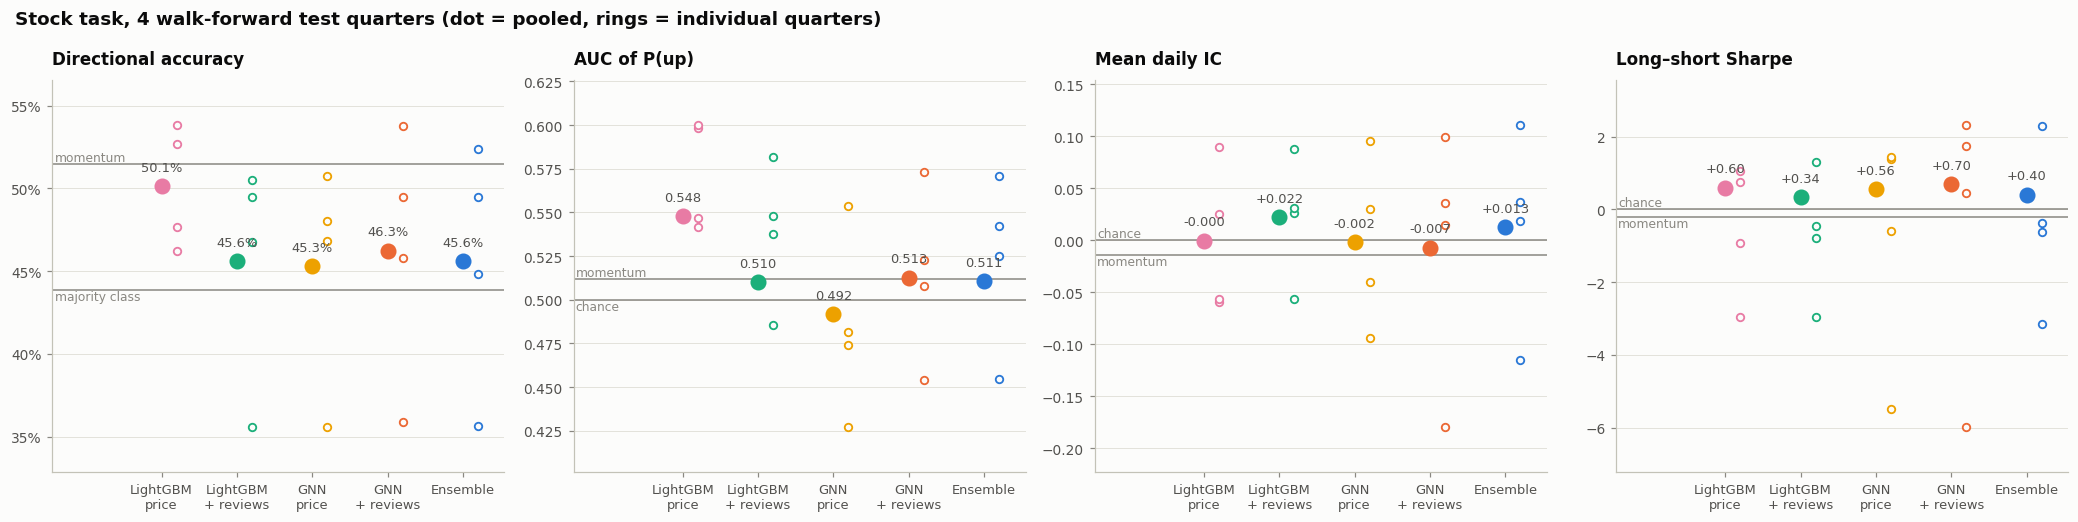

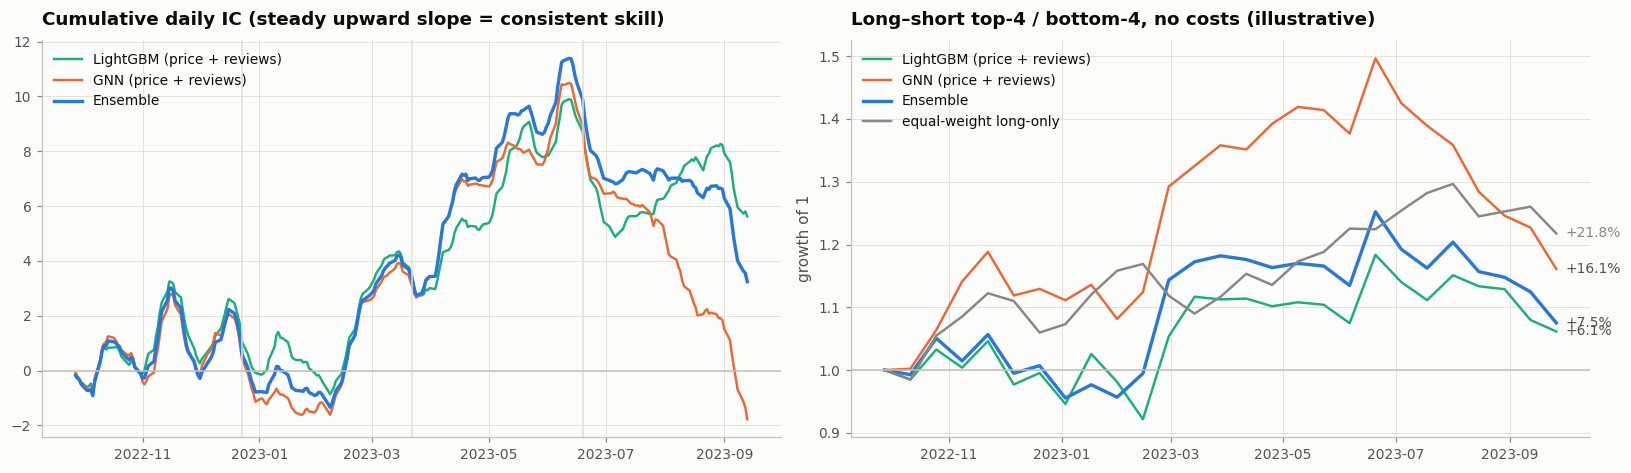

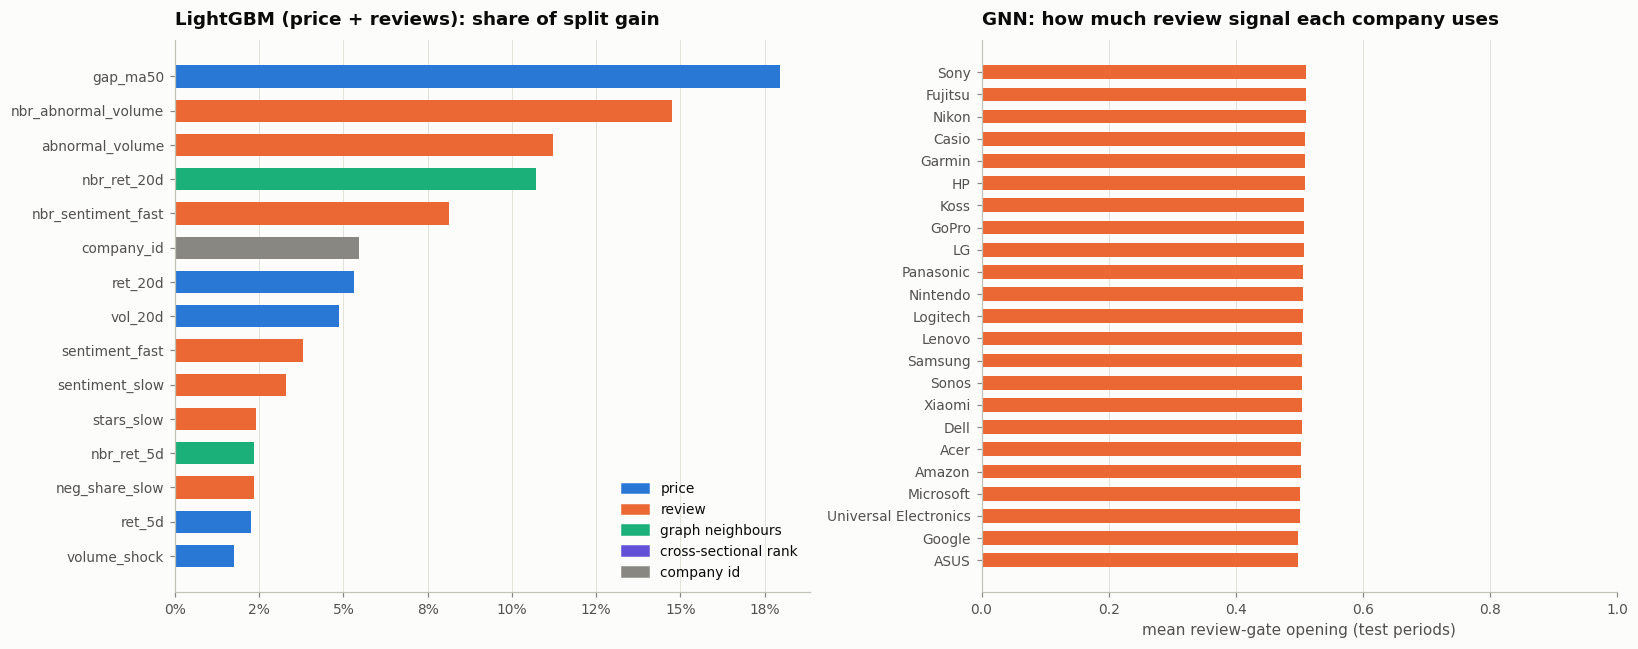

In [22]:
# Figure 10: model comparison (pooled = filled dot, each test quarter = ring)
panels = [("dir_acc", "Directional accuracy", "{:.1%}"), ("auc", "AUC of P(up)", "{:.3f}"),
          ("ic", "Mean daily IC", "{:+.3f}"), ("ls_sharpe", "Long–short Sharpe", "{:+.2f}")]
short = {"LightGBM (price)": "LightGBM\nprice", "LightGBM (price + reviews)": "LightGBM\n+ reviews",
         "GNN (price)": "GNN\nprice", "GNN (price + reviews)": "GNN\n+ reviews", "Ensemble": "Ensemble"}

def comparison_panel(ax, models, fold_df, pooled_res, key, title, fmt, refs):
    for x, m in enumerate(models):
        v = pooled_res[m][key]
        fv = fold_df.loc[fold_df["model"] == m, key].to_numpy(dtype=float)
        ax.scatter(np.full(len(fv), x + 0.2), fv, s=24, facecolor=SURFACE, edgecolor=MODEL_COLOR[m], linewidth=1.2, zorder=3)
        ax.scatter([x], [v], s=90, color=MODEL_COLOR[m], zorder=4)
        ax.annotate(fmt.format(v), (x, v), xytext=(0, 8), textcoords="offset points", ha="center", va="bottom",
                    fontsize=8.5, color=INK2)
    refs = sorted([r for r in refs if np.isfinite(r[0])], key=lambda r: r[0])
    ax.margins(y=0.15)
    y0, y1 = ax.get_ylim()
    for j, (v, lab) in enumerate(refs):
        ax.axhline(v, color=MUTED, lw=1, zorder=1)
        close_below = j > 0 and abs(v - refs[j - 1][0]) < 0.06 * (y1 - y0)
        ax.text(-1.42, v, f"{lab}", color=MUTED, fontsize=8, ha="left",
                va="bottom" if close_below or j == len(refs) - 1 else "top")
    ax.set_xticks(range(len(models)), labels=[short.get(m, m) for m in models], fontsize=8.5)
    ax.set_xlim(-1.45, len(models) - 0.45)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
for ax, (key, title, fmt) in zip(axes, panels):
    refs = [(STOCK_BASE[b][key], b.lower()) for b in STOCK_BASE if key != "auc" or b != "Majority class"]
    refs += [(0.5, "chance")] if key == "auc" else [(0.0, "chance")] if key in ("ic", "ls_sharpe") else []
    comparison_panel(ax, STOCK_MODELS, STOCK_FOLD_DF, STOCK_RES, key, title, fmt, refs)
axes[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
fig.suptitle(f"Stock task, {len(STOCK_FOLDS)} walk-forward test quarters (dot = pooled, rings = individual quarters)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "10_stock_results")

# Figure 11: is the skill steady? cumulative IC + illustrative backtest
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]
for m in ("LightGBM (price + reviews)", "GNN (price + reviews)", "Ensemble"):
    ics = pd.Series(STOCK_RES[m]["_ics"], index=P_DATES).fillna(0)
    ax.plot(ics.index, ics.cumsum(), color=MODEL_COLOR[m], lw=2.2 if m == "Ensemble" else 1.6, label=m)
for d in STOCK_DATA[1:]:
    ax.axvline(CAL[d["t"][0]], color=GRID, lw=1)
ax.axhline(0, color=AXIS, lw=1)
ax.set_title("Cumulative daily IC (steady upward slope = consistent skill)")
ax.legend(loc="upper left")
ax = axes[1]

def growth(r, H):
    dates = list(r.index) + [r.index[-1] + pd.Timedelta(days=int(H * 7 / 5))]
    return pd.Series(np.concatenate([[1.0], np.cumprod(1 + r.to_numpy())]), index=dates)

for m in ("LightGBM (price + reviews)", "GNN (price + reviews)", "Ensemble"):
    curve = growth(STOCK_RES[m]["_ls"]["long_short"], HORIZON)
    ax.plot(curve.index, curve.values, color=MODEL_COLOR[m], lw=2.2 if m == "Ensemble" else 1.6, label=m)
    ax.annotate(f"{curve.iloc[-1] - 1:+.1%}", (curve.index[-1], curve.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK2)
bench = growth(STOCK_RES["Ensemble"]["_ls"]["equal_weight"], HORIZON)
ax.plot(bench.index, bench.values, color=MUTED, lw=1.6, label="equal-weight long-only")
ax.annotate(f"{bench.iloc[-1] - 1:+.1%}", (bench.index[-1], bench.iloc[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=9, color=MUTED)
ax.axhline(1, color=AXIS, lw=1)
ax.set_title(f"Long–short top-{TOP_K_BACKTEST} / bottom-{TOP_K_BACKTEST}, no costs (illustrative)")
ax.set_ylabel("growth of 1")
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "11_stock_consistency")

# Figure 12: what drives the stock models?
imp = pd.concat(STOCK_IMPORTANCE, axis=1).mean(axis=1)
imp = (imp / imp.sum()).sort_values(ascending=True).tail(15)
group_of = lambda f: ("review" if f in REV_FEATS or "sentiment" in f or "abnormal" in f else
                      "graph neighbours" if f.startswith("nbr_") else "cross-sectional rank" if f.startswith("rank_")
                      else "company id" if f == "company_id" else "price")
GROUP_COLOR = {"price": SERIES[0], "review": SERIES[1], "graph neighbours": SERIES[2],
               "cross-sectional rank": SERIES[6], "company id": MUTED}
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw=dict(width_ratios=[1, 1]))
ax = axes[0]
ax.barh(range(len(imp)), imp.values, color=[GROUP_COLOR[group_of(f)] for f in imp.index], height=0.65)
ax.set_yticks(range(len(imp)), labels=imp.index)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("LightGBM (price + reviews): share of split gain")
ax.legend(handles=[mpl.patches.Patch(color=c, label=g) for g, c in GROUP_COLOR.items()], loc="lower right")
ax.grid(axis="y", visible=False)
ax = axes[1]
gate = np.mean(STOCK_GATES, axis=0)
o = np.argsort(gate)
ax.barh(np.arange(N), gate[o], color=SERIES[1], height=0.62)
ax.set_yticks(np.arange(N), labels=[NODES[i] for i in o])
ax.set_xlim(0, 1)
ax.set_xlabel("mean review-gate opening (test periods)")
ax.set_title("GNN: how much review signal each company uses")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "12_stock_drivers")

In [23]:
BRAND_HEADS = {"volume": ("reg", 1.0), "stars": ("reg", 1.0)}
BRAND_STREAMS = {"review": len(REVIEW_IDX), "market": len(MARKET_IDX)}
TARGETS = {"volume": (Y_VOL, M_VOL, BASE_VOL, np.log1p(cH / H_B)), "stars": (Y_STAR, M_STAR, BASE_STAR, sH)}

def brand_flat(Xb, ts):
    A = Xb[ts]
    parts, names = [A], list(BRAND_FEATS)
    raw_idx = [1, 3, 4, 6]
    parts.append(BR_RAW[ts][..., raw_idx])
    names += [f"raw_{BRAND_FEATS[j]}" for j in raw_idx]
    parts.append(np.stack([BASE_VOL["Long-run average"][ts], BASE_VOL["Same period last year"][ts],
                           BASE_STAR["Long-run average"][ts]], -1))
    names += ["base_volume_longrun", "base_volume_lastyear", "base_stars_longrun"]
    parts.append(np.einsum("ij,sjf->sif", G_BRAND["w_norm"], A[..., [1, 8]]))
    names += ["nbr_log_vol_4w", "nbr_sentiment_13w"]
    parts.append(np.broadcast_to(np.arange(N, dtype=float), A.shape[:2])[..., None])
    names += ["company_id"]
    F = np.concatenate(parts, -1)
    return F.reshape(-1, F.shape[-1]), names

def brand_fold(fold):
    fit_rows = np.arange(BRAND_T[0], fold["train"][-1] + 1)
    Xb, _, _ = standardize_panel(BR_RAW, fit_rows, skip=SEASON_IDX)
    tr = fold["train"]
    sd = {}
    for name, (Y, M, _, _) in TARGETS.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            s = np.nanstd(np.where(M[tr], Y[tr], np.nan), 0)
        sd[name] = np.where(np.isfinite(s) & (s > 1e-8), s, np.nanmedian(np.where(np.isfinite(s) & (s > 1e-8), s, np.nan)))

    def split(ts):
        flat, names = brand_flat(Xb, ts)
        out = dict(t=ts, flat=flat, names=names, y={}, raw={}, mask={},
                   x={"review": windows(Xb[..., REVIEW_IDX], ts, BRAND_LOOKBACK),
                      "market": windows(Xb[..., MARKET_IDX], ts, BRAND_LOOKBACK)})
        for name, (Y, M, _, _) in TARGETS.items():
            m = M[ts]
            out["raw"][name], out["mask"][name] = Y[ts], m
            out["y"][name] = np.stack([np.nan_to_num(Y[ts] / sd[name]), m], -1).astype(np.float32)
        return out
    return dict(sd=sd, train=split(tr), val=split(fold["val"]), test=split(fold["test"]))

def fit_lgbm_brand(D, target, params=None):
    def xy(split):
        m = D[split]["mask"][target].ravel()
        return D[split]["flat"][m], (D[split]["raw"][target] / D["sd"][target]).ravel()[m]
    model = fit_lgbm("reg", *xy("train"), *xy("val"), params)
    return model, lgbm_val_loss(model, *xy("val"))

def brand_eval(pred, actual, mask, now):
    m = mask & np.isfinite(pred) & np.isfinite(actual)
    if m.sum() < 10:
        return dict(skill=np.nan, dir_acc=np.nan, mae=np.nan, corr=np.nan, level_r2=np.nan)
    p, a = pred[m], actual[m]
    nz = (a != 0) & (p != 0)
    lvl_true, lvl_pred = now[m] + a, now[m] + p
    return dict(skill=float(1 - np.mean((p - a) ** 2) / np.mean(a ** 2)),
                dir_acc=float(np.mean(np.sign(p[nz]) == np.sign(a[nz]))) if nz.sum() > 10 else np.nan,
                mae=float(np.mean(np.abs(p - a))),
                corr=float(np.corrcoef(p, a)[0, 1]) if p.std() > 0 else np.nan,
                level_r2=float(1 - np.sum((lvl_pred - lvl_true) ** 2) / np.sum((lvl_true - lvl_true.mean()) ** 2)))

In [24]:
# ---- 10a. Tuning on fold 1 validation ------------------------------------------------------------------------
BD1 = brand_fold(BRAND_FOLDS[0])
rows = []
for g in LGB_GRID:
    rows.append({**g, "val_loss": sum(fit_lgbm_brand(BD1, t, g)[1] for t in TARGETS)})
LGB_TUNE_B = pd.DataFrame(rows).sort_values("val_loss").reset_index(drop=True)
BEST_LGB_BRAND = {k: int(LGB_TUNE_B.iloc[0][k]) for k in ("num_leaves", "min_child_samples")}
rows = []
for g in GNN_GRID:
    r = train_gnn(BRAND_STREAMS, BRAND_HEADS, G_BRAND["adj"], BD1, BRAND_LOOKBACK, seed=SEED, hp=g)
    rows.append({**g, "val_loss": r["best_val_loss"]})
    print(f"  GNN {g} → val loss {r['best_val_loss']:.4f}")
    del r
GNN_TUNE_B = pd.DataFrame(rows).sort_values("val_loss").reset_index(drop=True)
BEST_HP_BRAND = {"hidden": int(GNN_TUNE_B.iloc[0]["hidden"]), "dropout": float(GNN_TUNE_B.iloc[0]["dropout"])}
keras.backend.clear_session()
print("Brand task · selected LightGBM:", BEST_LGB_BRAND, "| selected GNN:", BEST_HP_BRAND)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

  GNN {'hidden': 16, 'dropout': 0.15} → val loss 1.1144
  GNN {'hidden': 16, 'dropout': 0.35} → val loss 1.0614
  GNN {'hidden': 32, 'dropout': 0.15} → val loss 1.3160
  GNN {'hidden': 32, 'dropout': 0.35} → val loss 1.1767
  GNN {'hidden': 64, 'dropout': 0.15} → val loss 1.2512
  GNN {'hidden': 64, 'dropout': 0.35} → val loss 1.1673
Brand task · selected LightGBM: {'num_leaves': 31, 'min_child_samples': 30} | selected GNN: {'hidden': 16, 'dropout': 0.35}


In [25]:
# ---- 10b. Walk-forward ----------------------------------------------------------------------------------------
BRAND_MODELS = ["LightGBM", "GNN", "Ensemble"]
BRAND_PRED = {t: {m: [] for m in BRAND_MODELS} for t in TARGETS}
BRAND_DATA, BRAND_IMPORTANCE, BRAND_GATES = [], {t: [] for t in TARGETS}, []
for k, fold in enumerate(BRAND_FOLDS):
    t0 = time.time()
    D = BD1 if k == 0 else brand_fold(fold)
    te = D["test"]
    for t in TARGETS:
        model, _ = fit_lgbm_brand(D, t, BEST_LGB_BRAND)
        BRAND_PRED[t]["LightGBM"].append(model.predict(te["flat"]).reshape(te["raw"][t].shape) * D["sd"][t])
        BRAND_IMPORTANCE[t].append(pd.Series(model.booster_.feature_importance(importance_type="gain"), index=te["names"]))
    runs = [train_gnn(BRAND_STREAMS, BRAND_HEADS, G_BRAND["adj"], D, BRAND_LOOKBACK, seed=SEED + 100 * k + s,
                      hp=BEST_HP_BRAND) for s in range(N_SEEDS)]
    for t in TARGETS:
        BRAND_PRED[t]["GNN"].append(np.mean([r["pred_test"][t] for r in runs], 0) * D["sd"][t])
        BRAND_PRED[t]["Ensemble"].append(0.5 * (BRAND_PRED[t]["GNN"][-1] + BRAND_PRED[t]["LightGBM"][-1]))
    BRAND_GATES.append(np.mean([r["explain"]["gate_market"].mean(axis=(0, 2)) for r in runs], 0))
    del runs
    keras.backend.clear_session()
    BRAND_DATA.append(dict(t=te["t"], raw=te["raw"], mask=te["mask"]))
    print(f"fold {k + 1}/{len(BRAND_FOLDS)} done in {time.time() - t0:.0f}s")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


fold 1/4 done in 42s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


fold 2/4 done in 34s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


fold 3/4 done in 57s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


fold 4/4 done in 42s


In [26]:
# ---- 10c. Results ---------------------------------------------------------------------------------------------
B_T = np.concatenate([d["t"] for d in BRAND_DATA])
brand_rows, brand_fold_rows = [], []
for t, (Y, M, BASE, NOW) in TARGETS.items():
    cands = {**{b: [BASE[b][d["t"]] for d in BRAND_DATA] for b in BASE if b != "Persistence"},
             **{m: BRAND_PRED[t][m] for m in BRAND_MODELS}}
    for m, preds in cands.items():
        e = brand_eval(np.vstack(preds), Y[B_T], M[B_T], NOW[B_T])
        brand_rows.append({"target": t, "model": m, **e})
        for k, d in enumerate(BRAND_DATA):
            ef = brand_eval(preds[k], Y[d["t"]], M[d["t"]], NOW[d["t"]])
            brand_fold_rows.append({"target": t, "model": m, "fold": k + 1, **ef})
BRAND_TABLE = pd.DataFrame(brand_rows)
BRAND_FOLD_DF = pd.DataFrame(brand_fold_rows)
print(f"Brand task · {len(BRAND_FOLDS)} test quarters · {WEEKS[B_T[0]].date()} → {WEEKS[B_T[-1]].date()}")
print("skill = 1 − MSE/MSE(persistence) · dir_acc = share of correctly predicted up/down changes · level_r2 = R² of the"
      " predicted 4-week level (high mostly because levels persist)\n")
for t in TARGETS:
    print(f"── {t} trend")
    print(BRAND_TABLE[BRAND_TABLE["target"] == t].drop(columns="target").set_index("model").to_string(), "\n")

Brand task · 4 test quarters · 2022-09-18 → 2023-08-13
skill = 1 − MSE/MSE(persistence) · dir_acc = share of correctly predicted up/down changes · level_r2 = R² of the predicted 4-week level (high mostly because levels persist)

── volume trend
                        skill  dir_acc    mae    corr  level_r2
model                                                          
Long-run average      -5.1649   0.4358 0.5693 -0.1580    0.8215
Same period last year -0.2533   0.6377 0.2645  0.1659    0.9637
LightGBM              -0.2227   0.3983 0.2742  0.1144    0.9646
GNN                   -0.1486   0.4254 0.2646  0.0171    0.9667
Ensemble              -0.1638   0.4128 0.2660  0.0815    0.9663 

── stars trend
                  skill  dir_acc    mae   corr  level_r2
model                                                   
Long-run average 0.3335   0.6855 0.1589 0.5989    0.3705
LightGBM         0.1788   0.6663 0.1649 0.4446    0.2244
GNN              0.0752   0.6000 0.1738 0.2766    0.1266
Ensem

In [ ]:
# %%
# ============================================================
# 10d. STAR-RATING DIRECTION: dedicated classifier
# Paste as a new cell after section 10c and run it. Uses only variables the notebook already made.
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# ---- features (all use data up to the current week only) ----
star2w = np.zeros((W, N))
np.add.at(star2w, (w_i, wn_i), rs["rating"].to_numpy()[okw].astype(float) ** 2)
cumc, cums, cums2 = np.cumsum(cw_, 0), np.cumsum(starw, 0), np.cumsum(star2w, 0)

def lag(a, k):
    out = np.full(a.shape, np.nan)
    out[k:] = a[:-k]
    return out

def past_mean(k=None):
    """Mean stars over the k weeks BEFORE the current 4-week window (None = all earlier history)."""
    c0, s0 = lag(cumc, H_B), lag(cums, H_B)
    if k is not None:
        c0 = c0 - np.nan_to_num(lag(cumc, H_B + k))
        s0 = s0 - np.nan_to_num(lag(cums, H_B + k))
    return ratio(s0, c0)

with np.errstate(invalid="ignore", divide="ignore"):
    sd_all = np.sqrt(np.maximum(cums2 / cumc - (cums / cumc) ** 2, 0.05))    # spread of a brand's star ratings
    se_now = sd_all / np.sqrt(np.maximum(cH, 1))                            # noise in the current 4-week average
dev_all = past_mean(None) - sH                 # > 0: current average is below the brand's usual level
DIR_FEATS = ["dev_all", "dev_52w", "dev_26w", "dev_13w", "z_all", "log_n_now", "last_change", "text_gap",
             "all_brand_dev", "season_sin", "season_cos"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    all_brand_dev = np.repeat(np.nanmean(dev_all, axis=1, keepdims=True), N, 1)
X_DIR = np.stack([
    dev_all, past_mean(52) - sH, past_mean(26) - sH, past_mean(13) - sH,
    np.clip(dev_all / se_now, -10, 10), np.log1p(cH), sH - lag(sH, H_B), senH - (sH - 3.0) / 2.0,
    all_brand_dev, np.repeat(season[:, None, 0], N, 1), np.repeat(season[:, None, 1], N, 1)], axis=-1)
X_DIR = np.nan_to_num(X_DIR, nan=0.0, posinf=0.0, neginf=0.0)
Y_DIR = (Y_STAR > 0).astype(int)
M_DIR = M_STAR & (Y_STAR != 0)
BASE_DIR = BASE_STAR["Long-run average"]       # simple rule: rating moves back toward the 52-week average

# ---- walk-forward: logistic regression + small LightGBM, averaged ----
def rows(ts):
    m = M_DIR[ts]
    return X_DIR[ts][m], Y_DIR[ts][m], BASE_DIR[ts][m]

dir_parts = []
for k, fold in enumerate(BRAND_FOLDS):
    Xtr, ytr, _ = rows(fold["train"])
    Xva, yva, _ = rows(fold["val"])
    Xte, yte, bte = rows(fold["test"])
    scaler = StandardScaler().fit(np.vstack([Xtr, Xva]))
    lr = LogisticRegression(C=0.5, max_iter=2000).fit(scaler.transform(np.vstack([Xtr, Xva])), np.concatenate([ytr, yva]))
    p_lr = lr.predict_proba(scaler.transform(Xte))[:, 1]
    gb = fit_lgbm("cls", Xtr, ytr, Xva, yva, dict(num_leaves=7, min_child_samples=30))
    p_gb = gb.predict_proba(Xte)[:, 1]
    dir_parts.append(pd.DataFrame({"fold": k + 1, "y": yte, "Logistic": p_lr, "LightGBM": p_gb,
                                   "Ensemble": 0.5 * (p_lr + p_gb), "base": bte}))
DIR = pd.concat(dir_parts, ignore_index=True)

# ---- results ----
def acc(p, y):
    return float(np.mean((p > 0.5) == (y == 1)))

def acc_at_coverage(conf, correct, share):
    n = max(1, int(round(share * len(conf))))
    return float(correct[np.argsort(-conf)[:n]].mean())

base_ok = (np.sign(DIR["base"]) == np.where(DIR["y"] == 1, 1, -1)).to_numpy()
print(f"Star-rating direction · {len(DIR):,} brand-weeks in {len(BRAND_FOLDS)} test blocks · share 'up' {DIR['y'].mean():.1%}\n")
print(f"  {'Simple rule (back to 52-week average)':<40} {base_ok.mean():.1%}")
for m in ("Logistic", "LightGBM", "Ensemble"):
    per_fold = " ".join(f"{acc(g[m], g['y']):.0%}" for _, g in DIR.groupby("fold"))
    print(f"  {m:<40} {acc(DIR[m], DIR['y']):.1%}   per block: {per_fold}")

SHARES = np.array([0.25, 0.5, 0.75, 1.0])
ens_ok = ((DIR["Ensemble"] > 0.5) == (DIR["y"] == 1)).to_numpy()
cov_model = [acc_at_coverage(np.abs(DIR["Ensemble"].to_numpy() - 0.5), ens_ok, s) for s in SHARES]
cov_base = [acc_at_coverage(np.abs(DIR["base"].to_numpy()), base_ok, s) for s in SHARES]
print("\nAccuracy when only the most confident calls are counted:")
for s, a, b in zip(SHARES, cov_model, cov_base):
    print(f"  most confident {s:>4.0%} of calls: ensemble {a:.1%} | simple rule {b:.1%}")

grid = np.linspace(0.1, 1.0, 19)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(grid, [acc_at_coverage(np.abs(DIR["base"].to_numpy()), base_ok, s) for s in grid], color=MUTED, lw=1.6,
        label="simple rule (back to 52-week average)")
ax.plot(grid, [acc_at_coverage(np.abs(DIR["Ensemble"].to_numpy() - 0.5), ens_ok, s) for s in grid], color=SERIES[0],
        label="ensemble classifier")
ax.axhline(0.75, color=AXIS, lw=1)
ax.text(0.1, 0.75, "75% target", color=MUTED, fontsize=8, va="bottom")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("share of brand-weeks where a call is made (most confident first)")
ax.set_ylabel("direction accuracy")
ax.set_title("Star-rating direction: accuracy vs how selective the model is")
ax.legend(loc="lower left")
fig.tight_layout()
savefig(fig, "16_star_direction")
DIR.to_csv(os.path.join(OUT_DIR, "brand_star_direction_predictions.csv"), index=False)

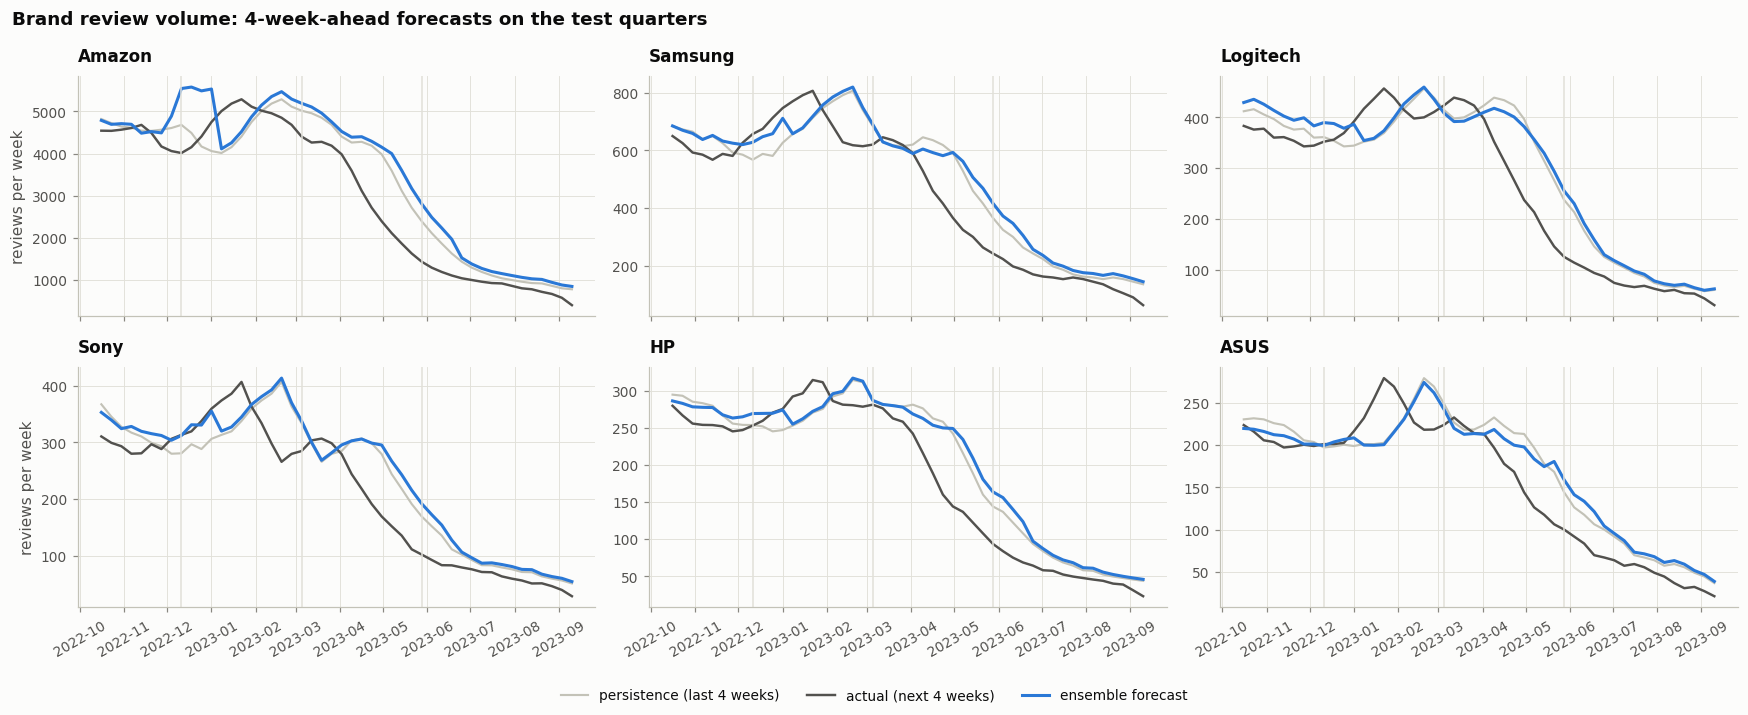

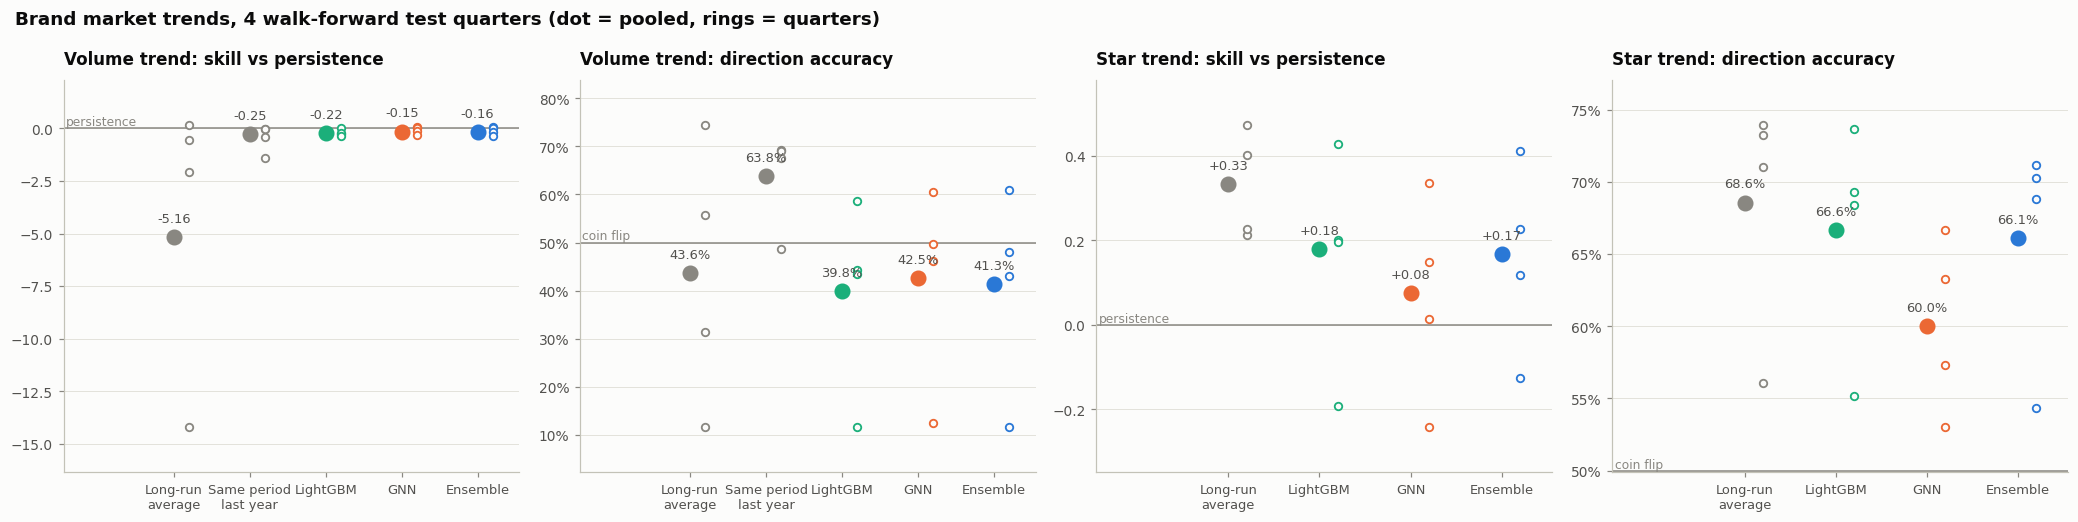

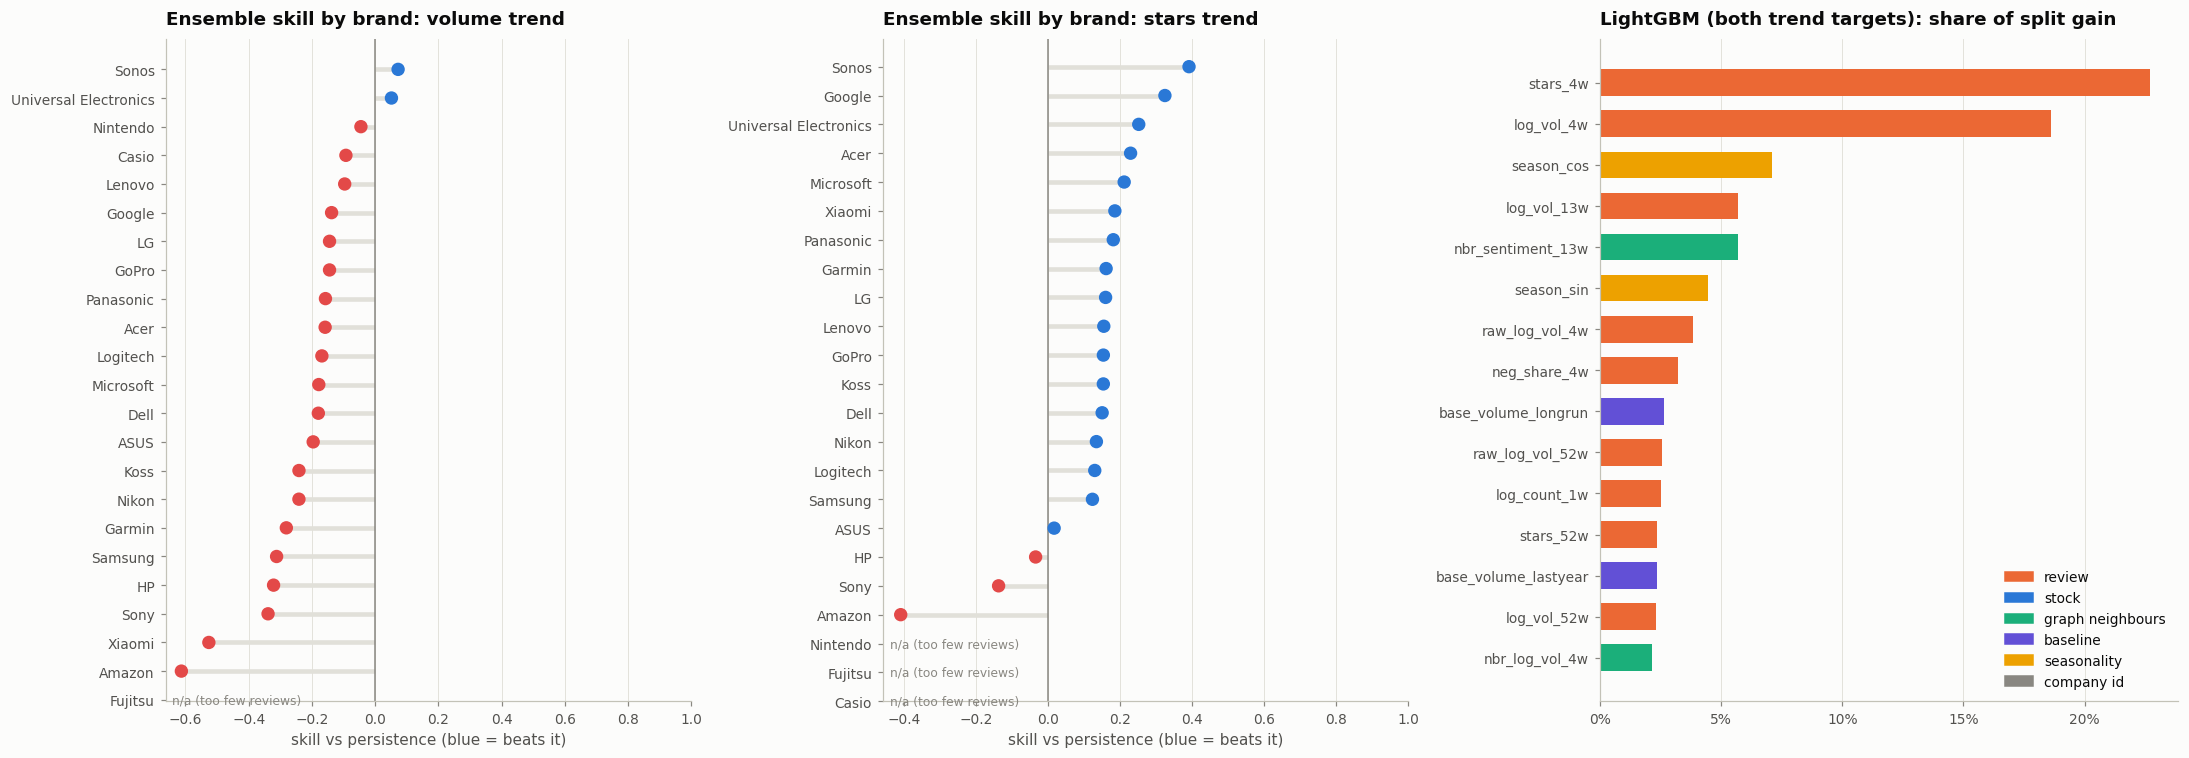

In [27]:
# Figure 13: forecasts vs reality for the six most-reviewed brands (volume, ensemble)
top6 = np.argsort(-cnt.sum(0))[:6]
Yv, Mv, _, NOWv = TARGETS["volume"]
ens_v = np.vstack(BRAND_PRED["volume"]["Ensemble"])
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5), sharex=True)
target_dates = WEEKS[np.minimum(B_T + H_B, W - 1)]
for ax, i in zip(axes.ravel(), top6):
    actual = np.expm1(NOWv[B_T, i] + Yv[B_T, i])
    ax.plot(target_dates, np.expm1(NOWv[B_T, i]), color=AXIS, lw=1.4, label="persistence (last 4 weeks)")
    ax.plot(target_dates, actual, color=INK2, lw=1.6, label="actual (next 4 weeks)")
    ax.plot(target_dates, np.expm1(NOWv[B_T, i] + ens_v[:, i]), color=SERIES[0], lw=2, label="ensemble forecast")
    for d in BRAND_DATA[1:]:
        ax.axvline(WEEKS[d["t"][0]], color=GRID, lw=1)
    ax.set_title(NODES[i], fontsize=11)
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].set_ylabel("reviews per week")
axes[1, 0].set_ylabel("reviews per week")
fig.suptitle("Brand review volume: 4-week-ahead forecasts on the test quarters", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=3)
savefig(fig, "13_brand_forecasts")

# Figure 14: brand results (pooled dot + quarter rings)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
short.update({"Long-run average": "Long-run\naverage", "Same period last year": "Same period\nlast year",
              "LightGBM": "LightGBM", "GNN": "GNN", "Ensemble": "Ensemble"})
for ax, (t, key, title, fmt) in zip(axes, [("volume", "skill", "Volume trend: skill vs persistence", "{:+.2f}"),
                                           ("volume", "dir_acc", "Volume trend: direction accuracy", "{:.1%}"),
                                           ("stars", "skill", "Star trend: skill vs persistence", "{:+.2f}"),
                                           ("stars", "dir_acc", "Star trend: direction accuracy", "{:.1%}")]):
    sub = BRAND_TABLE[BRAND_TABLE["target"] == t].set_index("model")
    models = list(sub.index)
    res = {m: {key: sub.loc[m, key]} for m in models}
    comparison_panel(ax, models, BRAND_FOLD_DF[BRAND_FOLD_DF["target"] == t], res, key, title, fmt,
                     [(0.0, "persistence")] if key == "skill" else [(0.5, "coin flip")])
    if key == "dir_acc":
        ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
fig.suptitle(f"Brand market trends, {len(BRAND_FOLDS)} walk-forward test quarters (dot = pooled, rings = quarters)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "14_brand_results")

# Figure 15: per-brand skill of the ensemble + what drives the brand models
fig, axes = plt.subplots(1, 3, figsize=(20, 7), gridspec_kw=dict(width_ratios=[1, 1, 1.1]))
for ax, t in zip(axes[:2], TARGETS):
    Y, M, _, _ = TARGETS[t]
    P = np.vstack(BRAND_PRED[t]["Ensemble"])
    sk = np.array([1 - np.nanmean(np.where(M[B_T, i], (P[:, i] - Y[B_T, i]) ** 2, np.nan)) /
                   np.nanmean(np.where(M[B_T, i], Y[B_T, i] ** 2, np.nan)) if M[B_T, i].sum() >= 8 else np.nan
                   for i in range(N)])
    o = np.argsort(np.nan_to_num(sk, nan=-9))
    ax.hlines(np.arange(N), 0, sk[o], color=GRID, lw=3)
    ax.scatter(sk[o], np.arange(N), s=60, color=[SERIES[0] if v > 0 else SERIES[7] for v in sk[o]], zorder=3)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(np.arange(N), labels=[NODES[i] for i in o])
    x_lo = min(0, max(-1, np.nanmin(sk) - 0.05)) if np.isfinite(sk).any() else -1
    ax.set_xlim(x_lo, 1)
    for y_, i in enumerate(o):
        if not np.isfinite(sk[i]):
            ax.text(x_lo + 0.02, y_, "n/a (too few reviews)", va="center", fontsize=8, color=MUTED)
    ax.set_title(f"Ensemble skill by brand: {t} trend")
    ax.set_xlabel("skill vs persistence (blue = beats it)")
    ax.grid(axis="y", visible=False)
ax = axes[2]
imp = pd.concat(BRAND_IMPORTANCE["volume"] + BRAND_IMPORTANCE["stars"], axis=1).mean(axis=1)
imp = (imp / imp.sum()).sort_values(ascending=True).tail(15)
bgroup = lambda f: ("baseline" if f.startswith("base_") else "graph neighbours" if f.startswith("nbr_")
                    else "stock" if f.startswith("stock_") else "seasonality" if f.startswith("season")
                    else "company id" if f == "company_id" else "review")
BGROUP_COLOR = {"review": SERIES[1], "stock": SERIES[0], "graph neighbours": SERIES[2], "baseline": SERIES[6],
                "seasonality": SERIES[3], "company id": MUTED}
ax.barh(range(len(imp)), imp.values, color=[BGROUP_COLOR[bgroup(f)] for f in imp.index], height=0.65)
ax.set_yticks(range(len(imp)), labels=imp.index)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title("LightGBM (both trend targets): share of split gain")
ax.legend(handles=[mpl.patches.Patch(color=c, label=g) for g, c in BGROUP_COLOR.items()], loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "15_brand_drivers")

In [28]:
# ---- 11. Save everything ----------------------------------------------------------------------------------------
STOCK_TABLE.to_csv(os.path.join(OUT_DIR, "stock_metrics_pooled.csv"))
STOCK_FOLD_DF.to_csv(os.path.join(OUT_DIR, "stock_metrics_by_quarter.csv"), index=False)
BRAND_TABLE.to_csv(os.path.join(OUT_DIR, "brand_metrics_pooled.csv"), index=False)
BRAND_FOLD_DF.to_csv(os.path.join(OUT_DIR, "brand_metrics_by_quarter.csv"), index=False)
pd.Series(TEXT_METRICS).to_csv(os.path.join(OUT_DIR, "transformer_metrics.csv"))
rows = []
for m in STOCK_MODELS:
    sc, pr = pooled(m, "score"), pooled(m, "prob")
    for s, t in enumerate(P_T):
        for i in range(N):
            if P_MASK[s, i]:
                rows.append((m, CAL[t].date(), NODES[i], sc[s, i], pr[s, i], P_RAW[s, i]))
pd.DataFrame(rows, columns=["model", "date", "company", "score", "p_up", f"realised_{HORIZON}d_logret"]) \
  .to_csv(os.path.join(OUT_DIR, "stock_test_predictions.csv"), index=False)
rows = []
for t, (Y, M, _, NOW) in TARGETS.items():
    P = np.vstack(BRAND_PRED[t]["Ensemble"])
    for s, w in enumerate(B_T):
        for i in range(N):
            if M[w, i]:
                rows.append((t, WEEKS[w].date(), NODES[i], NOW[w, i], P[s, i], Y[w, i]))
pd.DataFrame(rows, columns=["target", "week_end", "brand", "last_4w_level", "pred_change", "actual_change"]) \
  .to_csv(os.path.join(OUT_DIR, "brand_test_predictions.csv"), index=False)
json.dump({"TEXT_MODEL": TEXT_MODEL, "HORIZON": HORIZON, "BEST_HP_STOCK": BEST_HP_STOCK, "BEST_LGB_STOCK": BEST_LGB_STOCK,
           "BEST_HP_BRAND": BEST_HP_BRAND, "BEST_LGB_BRAND": BEST_LGB_BRAND, "NODES": NODES},
          open(os.path.join(OUT_DIR, "config_v2.json"), "w"), indent=2)
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/review_market_gnn_v2


In [29]:
def _f(v, f):
    return "n/a" if v is None or not np.isfinite(v) else f.format(v)

bt = BRAND_TABLE.set_index(["target", "model"])
best_brand = {t: bt.loc[t].drop(index=[b for b in bt.loc[t].index if b not in BRAND_MODELS])["skill"].idxmax() for t in TARGETS}
ens, maj = STOCK_RES["Ensemble"], STOCK_BASE["Majority class"]
lines = [
    f"**Transformer ({TEXT_MODEL}) on {TEXT_METRICS['n']:,} unseen test-period reviews:** "
    f"5-class accuracy {TEXT_METRICS['accuracy_5class']:.1%} (majority baseline {TEXT_METRICS['majority_baseline']:.1%}), "
    f"QWK {TEXT_METRICS['qwk']:.3f}, 3-class (neg/neu/pos) accuracy {TEXT_METRICS['accuracy_3class']:.1%}, "
    f"MAE of expected stars {TEXT_METRICS['mae_expected_stars']:.2f}.",
    "",
    f"**Task A: brand market trends** ({len(BRAND_FOLDS)} test quarters, {WEEKS[B_T[0]].date()} → {WEEKS[B_T[-1]].date()}):",
]
for t in TARGETS:
    m = best_brand[t]
    r = bt.loc[(t, m)]
    lr = bt.loc[(t, "Long-run average")]
    lines.append(f"- **{t} trend:** best model **{m}**, skill {_f(r['skill'], '{:+.2f}')} vs persistence; the long-run-average "
                 f"baseline alone reaches {_f(lr['skill'], '{:+.2f}')}, so the model's **added value is "
                 f"{_f(r['skill'] - lr['skill'], '{:+.2f}')}**. Direction accuracy {_f(r['dir_acc'], '{:.1%}')} "
                 f"(baseline {_f(lr['dir_acc'], '{:.1%}')}); R² of the 4-week level {_f(r['level_r2'], '{:.2f}')}.")
lines += [
    "",
    f"**Task B: stocks** (horizon {HORIZON} days, {len(STOCK_FOLDS)} test quarters, {P_DATES[0].date()} → {P_DATES[-1].date()}):",
    f"- Ensemble: directional accuracy {_f(ens['dir_acc'], '{:.1%}')} vs {_f(maj['dir_acc'], '{:.1%}')} majority class; "
    f"AUC {_f(ens['auc'], '{:.3f}')}; mean IC {_f(ens['ic'], '{:+.3f}')} (t ≈ {_f(ens['ic_t'], '{:.1f}')}); "
    f"long–short Sharpe {_f(ens['ls_sharpe'], '{:+.2f}')}; IC positive in {int((IC_FOLD('Ensemble') > 0).sum())}/{len(STOCK_FOLDS)} quarters.",
    f"- Reviews in LightGBM: IC {_f(STOCK_RES['LightGBM (price + reviews)']['ic'] - STOCK_RES['LightGBM (price)']['ic'], '{:+.3f}')}; "
    f"reviews in the GNN: IC {_f(STOCK_RES['GNN (price + reviews)']['ic'] - STOCK_RES['GNN (price)']['ic'], '{:+.3f}')} (pooled, vs price-only).",
    "",
]
brand_gain = {t: bt.loc[(t, best_brand[t]), "skill"] - bt.loc[(t, "Long-run average"), "skill"] for t in TARGETS}
brand_ok = all(np.isfinite(v) and v > 0.02 for v in brand_gain.values())
stock_ok = (np.isfinite(ens["ic_t"]) and ens["ic_t"] > 2 and (IC_FOLD("Ensemble") > 0).sum() >= len(STOCK_FOLDS) - 1)
lines.append("**Verdict.** " + (
    "Brand trends: the models beat both persistence and the long-run-average baseline on both targets, so this is the "
    "result to lead with. " if brand_ok else "Brand trends: most of the skill comes from reverting to the long-run level, "
    "which the baseline already captures; report the model and the baseline side by side. ")
    + ("Stocks: the ensemble's ranking skill is statistically distinguishable from zero and holds in most quarters."
       if stock_ok else "Stocks: no consistent skill beyond the baselines across quarters. That is the expected outcome "
       "for short stock horizons, and it is an honest result to report."))
SUMMARY_MD = "\n".join(lines)
try:
    from IPython.display import Markdown, display
    display(Markdown(SUMMARY_MD))
except Exception:
    print(SUMMARY_MD)
open(os.path.join(OUT_DIR, "results_summary_v2.md"), "w").write(SUMMARY_MD)

**Transformer (roberta-base) on 258,518 unseen test-period reviews:** 5-class accuracy 79.4% (majority baseline 63.9%), QWK 0.906, 3-class (neg/neu/pos) accuracy 91.0%, MAE of expected stars 0.49.

**Task A: brand market trends** (4 test quarters, 2022-09-18 → 2023-08-13):
- **volume trend:** best model **GNN**, skill -0.15 vs persistence; the long-run-average baseline alone reaches -5.16, so the model's **added value is +5.02**. Direction accuracy 42.5% (baseline 43.6%); R² of the 4-week level 0.97.
- **stars trend:** best model **LightGBM**, skill +0.18 vs persistence; the long-run-average baseline alone reaches +0.33, so the model's **added value is -0.15**. Direction accuracy 66.6% (baseline 68.6%); R² of the 4-week level 0.22.

**Task B: stocks** (horizon 10 days, 4 test quarters, 2022-09-27 → 2023-09-13):
- Ensemble: directional accuracy 45.6% vs 43.9% majority class; AUC 0.511; mean IC +0.013 (t ≈ 0.3); long–short Sharpe +0.40; IC positive in 3/4 quarters.
- Reviews in LightGBM: IC +0.022; reviews in the GNN: IC -0.005 (pooled, vs price-only).

**Verdict.** Brand trends: most of the skill comes from reverting to the long-run level, which the baseline already captures; report the model and the baseline side by side. Stocks: no consistent skill beyond the baselines across quarters. That is the expected outcome for short stock horizons, and it is an honest result to report.

1400